# Tutorial 0: EDA and Data Engineering
**AI Methods for Business, AUAS 2025-26**  
*AI-Powered Debt Collection Solution*

---

## Business case

A Dutch debt collection agency manages a portfolio of defaulted consumer debts.
Debtors have already missed payments. So the question is not *whether* they defaulted,
but what happens next:

- **Who will pay, and how much?** → determines which accounts to prioritise
- **Who will respond to contact?** → determines the contact strategy
- **Who is likely to dispute or complain?** → determines how carefully to handle the account

Right now these decisions are made by experience and gut feel. Our goal is to replace
gut feel with data-driven predictions. This tutorial lays the foundation:
understand the data, clean it, engineer features, and derive the targets that all
subsequent models will predict.

### The dataset

Four CSV files from the agency's own systems, covering accounts that defaulted
between 2020 and mid-2024:

| File | Rows | Description |
|---|---|---|
| `debtor_profiles.csv` | ~10,000 | One row per debtor. Demographics. |
| `accounts.csv` | ~14,000 | One row per debt account. Financial variables. |
| `payment_transactions.csv` | ~90,000 | One row per payment event. |
| `contact_history_enriched.csv` | ~111,000 | One row per contact attempt. Includes email and call text. |

### What we are predicting

| Target | Type | Window | Business question |
|---|---|---|---|
| `repayment_probability` | Binary classification | 90 days | Will this debtor make any payment? |
| `repayment_amount` | Regression | 90 days | How much will they pay in total? |
| `response_probability` | Binary classification | 30 days | Will this debtor respond to contact? |
| `complaint_risk` | Binary classification | No window | Will this debtor dispute or complain? |
| `time_to_repayment` | Regression (nullable) | no fixed window | How many days until first payment? |

> **Note:** Targets do not exist as columns in the raw data. We derive them in
> Section 8 from `payment_transactions` and `contact_history_enriched`.

## Section 1: Imports and data loading

In [1]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

# Plot style
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print('Libraries loaded successfully.')

Libraries loaded successfully.


In [2]:
# Load the four CSV files
DATA_DIR = "data/"

debtor_df  = pd.read_csv(DATA_DIR + 'debtor_profiles.csv')
acc_df     = pd.read_csv(DATA_DIR + 'accounts.csv')
tx_df      = pd.read_csv(DATA_DIR + 'payment_transactions.csv')
ch_df      = pd.read_csv(DATA_DIR + 'contact_history_enriched.csv')

print(f'debtor_profiles:          {debtor_df.shape[0]:>7,} rows  {debtor_df.shape[1]} columns')
print(f'accounts:                 {acc_df.shape[0]:>7,} rows  {acc_df.shape[1]} columns')
print(f'payment_transactions:     {tx_df.shape[0]:>7,} rows  {tx_df.shape[1]} columns')
print(f'contact_history_enriched: {ch_df.shape[0]:>7,} rows  {ch_df.shape[1]} columns')

debtor_profiles:           10,000 rows  11 columns
accounts:                  13,945 rows  12 columns
payment_transactions:      87,493 rows  10 columns
contact_history_enriched: 111,251 rows  15 columns


### Foreign key relationships

The four files are linked by two keys:
- `debtor_id`: links `debtor_profiles` → `accounts` → `payment_transactions` / `contact_history`
- `account_id`: links `accounts` → `payment_transactions` / `contact_history`

Before any analysis, we verify referential integrity: every `debtor_id` and `account_id`
in the transaction files should exist in the parent tables.

In [3]:
# Referential integrity checks
debtor_ids_valid = set(debtor_df['debtor_id'])
account_ids_valid = set(acc_df['account_id'])

checks = {
    'accounts → debtor_profiles (debtor_id)':
        acc_df['debtor_id'].isin(debtor_ids_valid).mean() * 100,
    'payment_transactions → accounts (account_id)':
        tx_df['account_id'].isin(account_ids_valid).mean() * 100,
    'contact_history → accounts (account_id)':
        ch_df['account_id'].isin(account_ids_valid).mean() * 100,
}

for check, pct in checks.items():
    status = 'OK' if pct == 100 else f'WARNING: {100-pct:.1f}% orphaned'
    print(f'  {check:<50} {pct:.1f}%  [{status}]')

  accounts → debtor_profiles (debtor_id)             100.0%  [OK]
  payment_transactions → accounts (account_id)       100.0%  [OK]
  contact_history → accounts (account_id)            100.0%  [OK]


**Expected:** near-100% match. Any orphaned rows are a data quality issue
introduced during the noise injection pass (realistic for real agency systems).

## Section 2: Initial inspection

Before any modelling, we inspect the raw structure of each file.
The goal is to develop intuition: what does the data look like? 
What distributions do we expect? What looks unusual?

In [4]:
# Column overview for each file
for name, df in [('debtor_profiles', debtor_df), ('accounts', acc_df),
                 ('payment_transactions', tx_df), ('contact_history_enriched', ch_df)]:
    print(f'\n=== {name} ===')
    print(df.dtypes.to_string())


=== debtor_profiles ===
debtor_id              object
date_of_birth          object
gender                 object
country_of_origin      object
born_in_netherlands    object
employment_status      object
income_band            object
education_level        object
household_type         object
postcode               object
urban_category         object

=== accounts ===
account_id               object
debtor_id                object
client_id                object
debt_type                object
original_amount         float64
outstanding_balance     float64
days_past_due           float64
missed_payments         float64
interest_rate           float64
broken_arrangements     float64
account_default_date     object
status                   object

=== payment_transactions ===
transaction_id       object
account_id           object
debtor_id            object
transaction_date     object
amount_paid         float64
payment_method       object
channel              object
arrangement_id   

In [5]:
# Descriptive statistics for numeric columns
print('=== accounts: numeric summary ===')
display(acc_df[['original_amount','outstanding_balance','days_past_due',
                'missed_payments','interest_rate','broken_arrangements']].describe().round(2))

print('\n=== payment_transactions: numeric summary ===')
display(tx_df[['amount_paid']].describe().round(2))

print('\n=== contact_history: numeric summary ===')
display(ch_df[['cost']].describe().round(2))

=== accounts: numeric summary ===


,original_amount,outstanding_balance,days_past_due,missed_payments,interest_rate,broken_arrangements
count,13945.00,13945.00,13876.00,13945.00,13945.00,13904.00
mean,2231.60,1638.05,350.00,11.21,5.32,1.31
std,3774.70,3137.78,216.04,7.28,6.88,1.46
min,50.00,0.00,30.00,1.00,0.00,0.00
25%,324.87,177.72,165.00,5.00,0.00,0.00
50%,626.25,395.72,325.00,10.00,0.00,1.00
75%,2439.82,1575.41,485.00,16.00,11.18,2.00
max,25000.00,31450.81,996.00,35.00,20.00,6.00



=== payment_transactions: numeric summary ===


,amount_paid
count,87493.00
mean,88.09
std,338.40
min,1.00
25%,5.00
50%,19.58
75%,51.31
max,30122.80



=== contact_history: numeric summary ===


,cost
count,105689.00
mean,3.59
std,7.69
min,0.01
25%,0.14
50%,2.29
75%,3.86
max,62.07


### 2.1 Histograms: numeric columns

Documentation: [matplotlib.pyplot.hist](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html)

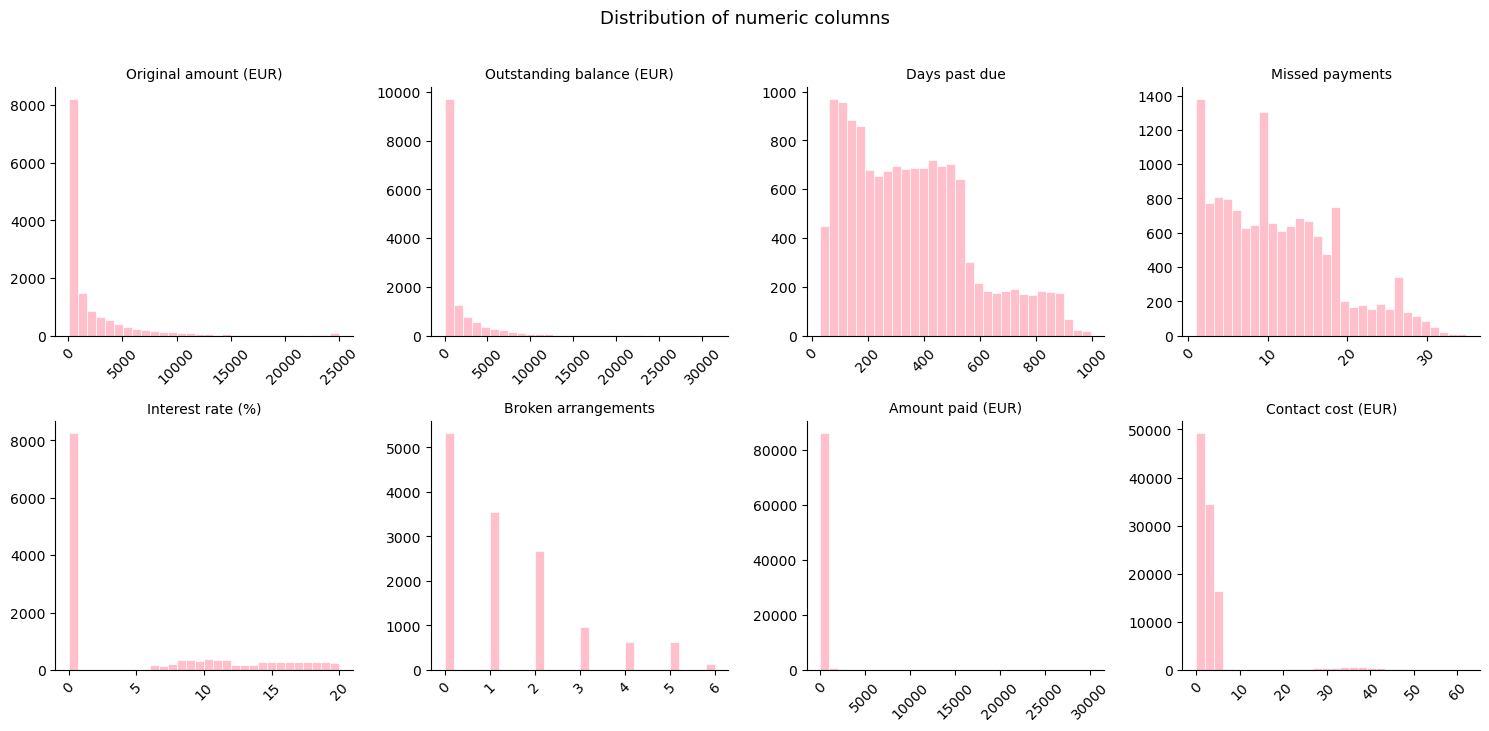

In [6]:
fig = plt.figure(figsize=(15, 10))
gs = gridspec.GridSpec(3, 4, figure=fig)

numeric_plots = [
    (acc_df,  'original_amount',      'Original amount (EUR)',      fig.add_subplot(gs[0, 0])),
    (acc_df,  'outstanding_balance',  'Outstanding balance (EUR)',  fig.add_subplot(gs[0, 1])),
    (acc_df,  'days_past_due',        'Days past due',              fig.add_subplot(gs[0, 2])),
    (acc_df,  'missed_payments',      'Missed payments',            fig.add_subplot(gs[0, 3])),
    (acc_df,  'interest_rate',        'Interest rate (%)',          fig.add_subplot(gs[1, 0])),
    (acc_df,  'broken_arrangements',  'Broken arrangements',        fig.add_subplot(gs[1, 1])),
    (tx_df,   'amount_paid',          'Amount paid (EUR)',          fig.add_subplot(gs[1, 2])),
    (ch_df,   'cost',                 'Contact cost (EUR)',         fig.add_subplot(gs[1, 3])),
]

for df, col, title, ax in numeric_plots:
    ax.hist(df[col].dropna(), bins=30, color='pink', edgecolor='white', linewidth=0.5)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('')
    # Rotate the xticks to 45 degrees
    ax.tick_params(axis='x', rotation=45)


plt.suptitle('Distribution of numeric columns', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

**QUESTION:** Several of the numeric columns above are visibly right-skewed (a long tail of high values). Which modelling techniques are sensitive to this skew, and which are naturally more robust to it?

From the histograms above:
- `original_amount` and `outstanding_balance` are **right-skewed**: most debts are small
  but a few are very large. A log transform will likely be needed before modelling.
- `days_past_due` is **bimodal**: one peak around 60-180 days (active collection)
  and another around 600-900 days (non-responders and disputed accounts).
- `interest_rate` has a spike at 0%: utilities, medical bills, and BNPL accounts
  carry no interest by law.
- `amount_paid` is heavily right-skewed with outliers: likely includes transcription
  errors (amounts entered as 10x their true value) from the noise injection.

**QUESTION:** Which of these distributions suggest we should check for outliers
before using the variable as a model feature?

### 2.2 Bar charts: categorical columns

Documentation: [seaborn.countplot](https://seaborn.pydata.org/generated/seaborn.countplot.html)

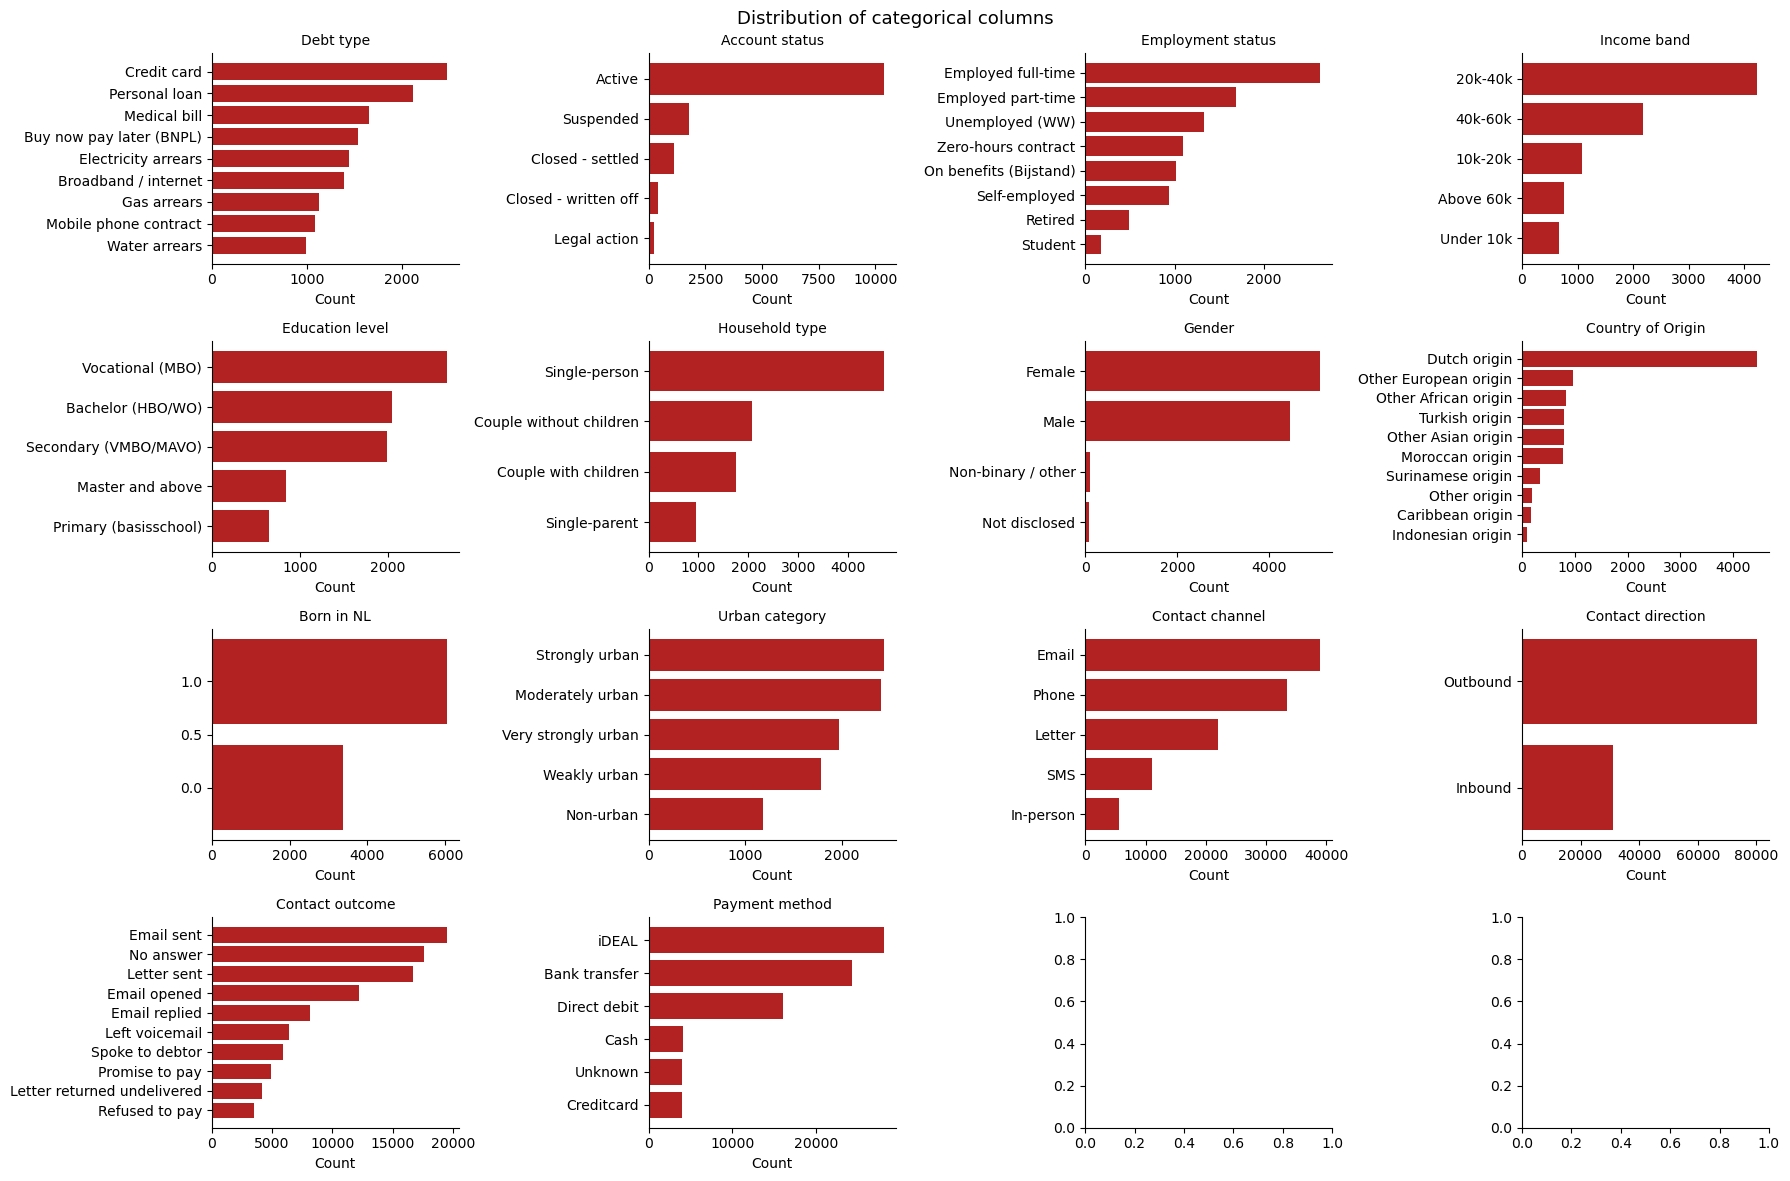

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(18, 12))
axes = axes.flatten()

cat_plots = [
    (acc_df,    'debt_type',          'Debt type'),
    (acc_df,    'status',             'Account status'),
    (debtor_df, 'employment_status',  'Employment status'),
    (debtor_df, 'income_band',        'Income band'),
    (debtor_df, 'education_level',    'Education level'),
    (debtor_df, 'household_type',     'Household type'),
    (debtor_df, 'gender',             'Gender'),
    (debtor_df, 'country_of_origin',  'Country of Origin'),
    (debtor_df, 'born_in_netherlands','Born in NL'),
    (debtor_df, 'urban_category',     'Urban category'),
    (ch_df,     'channel',            'Contact channel'),
    (ch_df,     'direction',          'Contact direction'),
    (ch_df,     'outcome',            'Contact outcome'),
    (tx_df,     'payment_method',     'Payment method'),
]

for i, (df, col, title) in enumerate(cat_plots):
    vc = df[col].value_counts().head(10)
    axes[i].barh(vc.index[::-1], vc.values[::-1], color='firebrick')
    axes[i].set_title(title, fontsize=10)
    axes[i].set_xlabel('Count')

plt.suptitle('Distribution of categorical columns', fontsize=13)
plt.tight_layout()
plt.show()

**QUESTION:** Some categories above have very few observations, a long tail of rare values. What problems could a rare category cause once you one-hot encode it and then split into train, val, and test?

Key observations:
- `debt_type`: personal loans and credit cards dominate, but utility arrears and BNPL
  are well represented.  Note the latter have different null patterns.
- `employment_status`: full-time employed is the largest group but unemployed, bijstand,
  and zero-hours contracts are significantly overrepresented vs the general population.
- `outcome`: "No answer" and "Email sent" are the most common outcomes and
  most contact attempts do not result in a meaningful response.
- `income_band` and `education_level` will have high null rates. We will quantify this in Section 4.

## Section 3: Time-based train/val/test split

### Why time-based splitting?

In a production debt collection system, the model is trained on historical accounts
and deployed to score new incoming defaults. If we split randomly, accounts that
defaulted in 2024 could appear in the training set, meaning the model learns from
future data to predict past outcomes which is called **temporal leakage**.

Time-based splitting mirrors the production setting:
- **Train:** accounts defaulting 2020-01-01 to 2022-12-31
- **Val:** accounts defaulting 2023-01-01 to 2023-12-31  
- **Test:** accounts defaulting 2024-01-01 to 2024-06-30

> **The test set is sacred.** We do not inspect it, impute it, or encode it until
> all fitting decisions are made on the training set. Any property of the test set
> used during training will bias the model evaluation.

Documentation: [pandas.to_datetime](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html)

In [8]:
# Parse account_default_date and coerce malformed values to NaT
acc_df['default_date_parsed'] = pd.to_datetime(acc_df['account_default_date'], errors='coerce')

# Count malformed dates
n_malformed = acc_df['default_date_parsed'].isna().sum()
n_total = len(acc_df)
print(f'Malformed account_default_date: {n_malformed} ({n_malformed/n_total*100:.1f}%)')
print(f'Sample malformed values: {acc_df[acc_df["default_date_parsed"].isna()]["account_default_date"].value_counts().head(5).to_dict()}')

Malformed account_default_date: 315 (2.3%)
Sample malformed values: {'00-00-0000': 83, '11/18/2020': 2, '09/25/2020': 2, '01/04/2021': 2, '10/29/2020': 2}


In [9]:
# Define split boundaries
TRAIN_START = pd.Timestamp('2020-01-01')
TRAIN_END   = pd.Timestamp('2022-12-31')
VAL_START   = pd.Timestamp('2023-01-01')
VAL_END     = pd.Timestamp('2023-12-31')
TEST_START  = pd.Timestamp('2024-01-01')
TEST_END    = pd.Timestamp('2024-06-30')

def assign_split(date):
    """Assigns a dataset split (train, val, test, or unknown) based on a given date.

    Args:
        date (pd.Timestamp or datetime or pd.NaT): The date to evaluate.

    Returns:
        str: The assigned dataset split name ('train', 'val', 'test', or 'unknown').
    """
    if pd.isna(date):
        return 'unknown'
    if TRAIN_START <= date <= TRAIN_END:
        return 'train'
    if VAL_START <= date <= VAL_END:
        return 'val'
    if TEST_START <= date <= TEST_END:
        return 'test'
    return 'unknown'

acc_df['split'] = acc_df['default_date_parsed'].apply(assign_split)

print('Account split distribution:')
print(acc_df['split'].value_counts())

Account split distribution:
split
train      8968
val        3115
test       1547
unknown     315
Name: count, dtype: int64


In [10]:
# Propagate split labels to other files via account_id

# Convert account IDs and splits into a lookup dictionary
account_split_map = acc_df.set_index('account_id')['split'].to_dict()

# Group by debtor, find the most frequent split per debtor, and convert to a dictionary
debtor_split_map  = acc_df.groupby('debtor_id')['split'].agg(
    lambda x: x.mode()[0] if len(x) > 0 else 'unknown').to_dict()

# Map splits to transaction data based on account ID; fill missing values with unknown
tx_df['split']     = tx_df['account_id'].map(account_split_map).fillna('unknown')

# Map splits to contact history based on account ID; fill missing values with unknown
ch_df['split']     = ch_df['account_id'].map(account_split_map).fillna('unknown')

# Map splits to debtor data based on debtor ID; fill missing values with unknown
debtor_df['split'] = debtor_df['debtor_id'].map(debtor_split_map).fillna('unknown')

# Summary
for name, df in [('accounts', acc_df), ('payment_transactions', tx_df),
                 ('contact_history', ch_df), ('debtor_profiles', debtor_df)]:
    counts = df['split'].value_counts()
    print(f'{name:<30} train={counts.get("train",0):>6,}  val={counts.get("val",0):>5,}  test={counts.get("test",0):>5,}')

accounts                       train= 8,968  val=3,115  test=1,547
payment_transactions           train=68,352  val=12,569  test=4,362
contact_history                train=71,456  val=25,190  test=12,006
debtor_profiles                train= 6,732  val=1,685  test=1,407


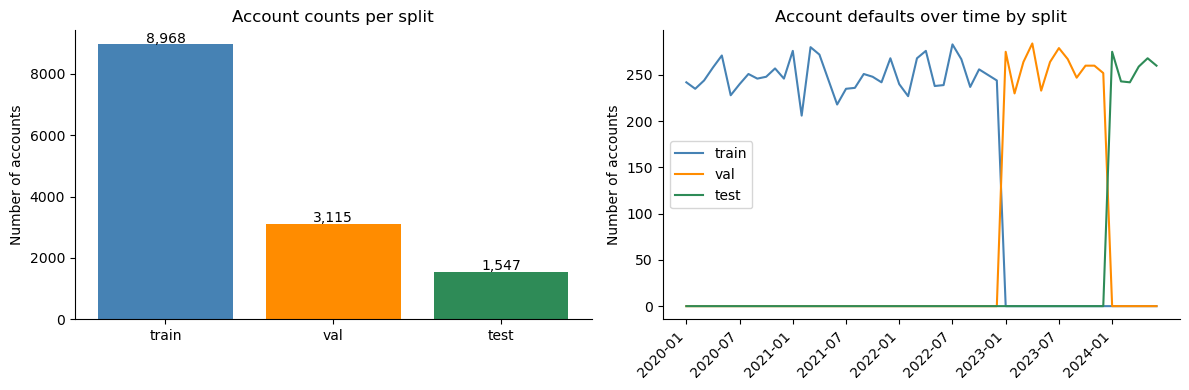

In [11]:
# Visualise split distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart: account counts per split
split_counts = acc_df[acc_df['split'] != 'unknown']['split'].value_counts().reindex(['train','val','test'])
axes[0].bar(split_counts.index, split_counts.values, color=['steelblue','darkorange','seagreen'])
for i, (idx, val) in enumerate(split_counts.items()):
    axes[0].text(i, val + 50, f'{val:,}', ha='center', fontsize=10)
axes[0].set_title('Account counts per split')
axes[0].set_ylabel('Number of accounts')

# Line chart: accounts over time coloured by split
valid = acc_df[acc_df['default_date_parsed'].notna()].copy()
valid['year_month'] = valid['default_date_parsed'].dt.to_period('M')
monthly = valid.groupby(['year_month','split']).size().unstack(fill_value=0)
for col, colour in [('train','steelblue'),('val','darkorange'),('test','seagreen')]:
    if col in monthly.columns:
        axes[1].plot(monthly.index.astype(str), monthly[col], label=col, color=colour)
axes[1].set_xticks(range(0, len(monthly), 6))
axes[1].set_xticklabels(monthly.index[::6].astype(str), rotation=45, ha='right')
axes[1].set_title('Account defaults over time by split')
axes[1].set_ylabel('Number of accounts')
axes[1].legend()

plt.tight_layout()
plt.show()

**QUESTION:** Why do we assign the train, val, and test split based on account_default_date rather than a random shuffle? What would go wrong if we used a random split here instead?

**From this point forward, all EDA, fitting, and encoding uses the TRAINING SET only.**

Parameters learned on train (imputation values, encoder categories,
scaler ranges) are applied to val and test without refitting.

## Section 4: Missing value analysis (train only)

### Theory: Missing data mechanisms

Missing data falls into three categories:

- **MCAR** (Missing Completely At Random): missingness is independent of any variable.
  Safe to drop or impute naively.
- **MAR** (Missing At Random): missingness depends on *observed* variables.
  Group-wise imputation is appropriate.
- **MNAR** (Missing Not At Random): missingness depends on the *unobserved* value
  itself or on an external variable not in the dataset.
  Naive imputation produces biased estimates.

In our dataset, `income_band` is more likely to be missing for BNPL and utility
debtors because those creditors did not collect income data. This is **MNAR**:
the reason for missingness is directly related to the debt type, which we can observe.
If we impute `income_band` using the overall training mean, we implicitly assume the
income of BNPL debtors is the same as the rest of the portfolio, which is wrong.

**The correct approach:** group-wise imputation within debt type.

Documentation: [pandas.DataFrame.isnull](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html)

In [12]:
## Compute null rates on train split only

# Filter each DataFrame to isolate only the training split rows
train_debtor = debtor_df[debtor_df['split'] == 'train'].copy()
train_acc    = acc_df[acc_df['split'] == 'train'].copy()
train_tx     = tx_df[tx_df['split'] == 'train'].copy()
train_ch     = ch_df[ch_df['split'] == 'train'].copy()

# Initialize dictionary to store computed missing value percentages
null_rates = {}
# Loop through named DataFrames to calculate missing data metrics
for name, df in [('debtor_profiles', train_debtor), ('accounts', train_acc),
                 ('payment_transactions', train_tx), ('contact_history', train_ch)]:
    # Check every column inside the current DataFrame
    for col in df.columns:
        # Calculate percentage of missing values in the column
        rate = df[col].isna().mean() * 100
         # If any data is missing, store the rate with a table-qualified key
        if rate > 0:
            null_rates[f'{name}.{col}'] = rate

# Convert results to a Series sorted by highest missing rate first
null_series = pd.Series(null_rates).sort_values(ascending=False)

print('Columns with missing values (train split):')
print(null_series.to_string())

Columns with missing values (train split):
payment_transactions.arrangement_id        95.174977
contact_history.call_transcript_snippet    81.052676
payment_transactions.notes                 70.069640
contact_history.email_subject              64.971451
contact_history.email_body_snippet         64.971451
contact_history.follow_up_date             62.579769
contact_history.contact_time               34.838222
contact_history.agent_id                   25.295287
debtor_profiles.education_level            18.374926
debtor_profiles.income_band                11.081402
payment_transactions.payment_method         7.932467
debtor_profiles.employment_status           6.699346
contact_history.outcome                     5.957512
debtor_profiles.born_in_netherlands         5.763518
debtor_profiles.country_of_origin           5.763518
debtor_profiles.household_type              5.184195
contact_history.cost                        4.982087
debtor_profiles.date_of_birth               4.070113
deb

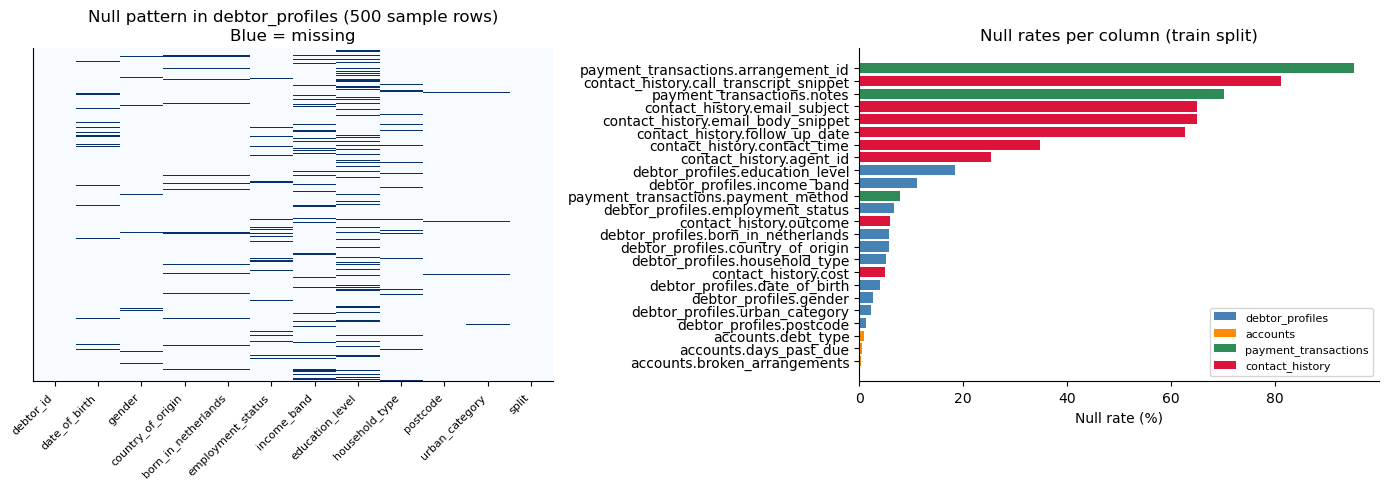

In [13]:
# Heatmap: null pattern in debtor_profiles (train)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap of null pattern (sample 500 rows for visibility)
sample = train_debtor.sample(min(500, len(train_debtor)), random_state=42)
null_mask = sample.isnull()
axes[0].imshow(null_mask.values, aspect='auto', cmap='Blues', interpolation='none')
axes[0].set_xticks(range(len(sample.columns)))
axes[0].set_xticklabels(sample.columns, rotation=45, ha='right', fontsize=8)
axes[0].set_yticks([])
axes[0].set_title('Null pattern in debtor_profiles (500 sample rows)\nBlue = missing')

# Sorted bar chart: null rates per column coloured by file
colours = {'debtor_profiles': 'steelblue', 'accounts': 'darkorange',
           'payment_transactions': 'seagreen', 'contact_history': 'crimson'}
bar_colours = [colours[k.split('.')[0]] for k in null_series.index]
axes[1].barh(null_series.index[::-1], null_series.values[::-1], color=bar_colours[::-1])
axes[1].set_xlabel('Null rate (%)')
axes[1].set_title('Null rates per column (train split)')
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=n) for n,c in colours.items()]
axes[1].legend(handles=legend_elements, loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()

**QUESTION:** Some columns cluster together in their null pattern: their missing rows tend to coincide. What might explain that, and how would you check the explanation directly rather than just eyeballing the heatmap?

### 4.1 MNAR diagnosis: debt-type correlated nulls

We test formally whether null rates in `income_band`, `employment_status`, and
`date_of_birth` depend on debt type.

**Chi-square test of independence** ($\chi^2$):
- $H_0$: the null rate is independent of debt type
- $H_1$: the null rate depends on debt type
- Reject $H_0$ when $p < 0.05$

$$\chi^2 = \sum \frac{(O - E)^2}{E}$$

where $O$ = observed frequency, $E$ = expected frequency under independence.

Documentation: [scipy.stats.chi2_contingency](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html)

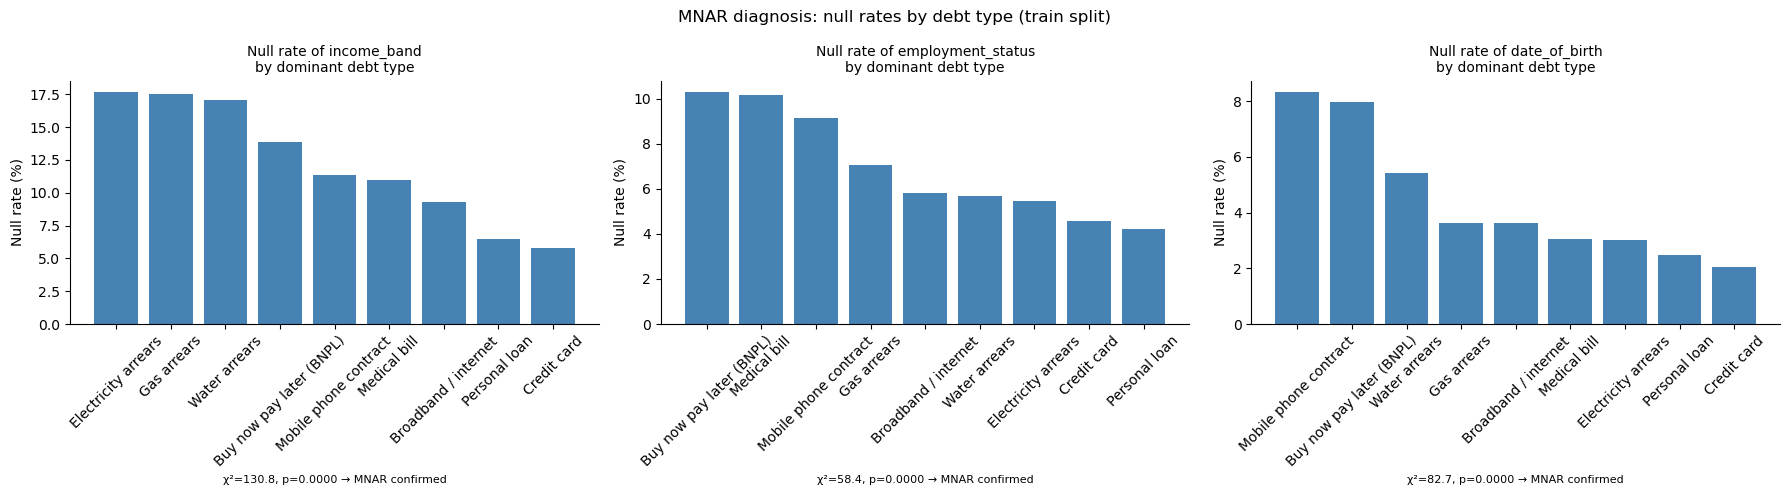

In [14]:
# Join debtor_profiles to accounts to get dominant debt type per debtor (train only)
train_acc_clean = train_acc.dropna(subset=['debt_type'])
dominant_debt = (train_acc_clean.groupby('debtor_id')['debt_type']
                  .agg(lambda x: x.mode()[0])
                  .reset_index()
                  .rename(columns={'debt_type': 'dominant_debt_type'}))

train_debtor_with_debt = train_debtor.merge(dominant_debt, on='debtor_id', how='left')

# Chi-square tests and grouped bar charts
mnar_cols = ['income_band', 'employment_status', 'date_of_birth']
alpha = 0.05

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(mnar_cols):
    if col not in train_debtor_with_debt.columns:
        continue
    # Null rates per debt type group
    null_by_type = (train_debtor_with_debt
                    .groupby('dominant_debt_type')[col]
                    .apply(lambda x: x.isna().mean() * 100)
                    .sort_values(ascending=False))

    axes[i].bar(null_by_type.index, null_by_type.values, color='steelblue')
    axes[i].set_title(f'Null rate of {col}\nby dominant debt type', fontsize=10)
    axes[i].set_ylabel('Null rate (%)')
    axes[i].tick_params(axis='x', rotation=45)

    # Chi-square test
    is_null = train_debtor_with_debt[col].isna().astype(int)
    contingency = pd.crosstab(train_debtor_with_debt['dominant_debt_type'], is_null)
    chi2, p, dof, _ = stats.chi2_contingency(contingency)
    conclusion = 'MNAR confirmed' if p < alpha else 'Cannot confirm MNAR'
    axes[i].set_xlabel(f'χ²={chi2:.1f}, p={p:.4f} → {conclusion}', fontsize=8)

plt.suptitle('MNAR diagnosis: null rates by debt type (train split)', fontsize=12)
plt.tight_layout()
plt.show()

### 4.2 Structural cascade validation

Two cascades were designed into the noise injection:
1. `urban_category` is **always null** when `postcode` is null or malformed
2. `born_in_netherlands` is **always null** when `country_of_origin` is null

We verify these hold, and also visualise them. These cascades have implications
for imputation: you cannot impute `urban_category` without first recovering the
postcode, and you cannot impute `born_in_netherlands` without first knowing the origin.

In [15]:
# Cascade 1: postcode validity → urban_category

# Helper function to validate Dutch-style 4-digit numeric postcodes
def is_valid_postcode(pc):
    """Validates if a given input is a valid 4-digit numeric postcode.

    Args:
        pc (int, float, str, or pd.NA): The postcode value to evaluate. Can be 
            numeric, a string representation of a number, or missing data.

    Returns:
        bool: True if the input is a valid 4-digit numeric string (after 
            stripping whitespace), False otherwise or if the input is null.
    """
    # Return False immediately if the postcode is missing
    if pd.isna(pc):
        return False
    # Remove leading/trailing spaces and cast to string
    s = str(pc).strip()
    # Check if the cleaned string is exactly 4 digits long
    return len(s) == 4 and s.isdigit()

# Add a boolean column marking whether each postcode is valid
train_debtor['postcode_valid'] = train_debtor['postcode'].apply(is_valid_postcode)

# Add a boolean column marking whether urban_category is missing
train_debtor['urban_null']     = train_debtor['urban_category'].isna()

# Cross-tabulation
# Create a contingency table comparing postcode validity against missing urban categories
ct1 = pd.crosstab(train_debtor['postcode_valid'], train_debtor['urban_null'],
                  rownames=['postcode valid'], colnames=['urban_category null'])

# Display section header
print('Cascade 1: postcode validity vs urban_category null')

# Print the calculated contingency table
print(ct1)

# Count rows failing the rule (invalid postcode but urban_category is present)
n_violation = train_debtor[~train_debtor['postcode_valid'] & ~train_debtor['urban_null']].shape[0]
# Print total count of rule violations found
print(f'Violations (bad postcode but urban_category not null): {n_violation}')

## Cascade 2: country_of_origin null → born_in_netherlands null

# Add a boolean column marking whether country_of_origin is missing
train_debtor['origin_null'] = train_debtor['country_of_origin'].isna()

# Add a boolean column marking whether born_in_netherlands is missing
train_debtor['born_null']   = train_debtor['born_in_netherlands'].isna()

# Create a contingency table comparing missing origins against missing birth locations
ct2 = pd.crosstab(train_debtor['origin_null'], train_debtor['born_null'],
                  rownames=['country_of_origin null'], colnames=['born_in_netherlands null'])

# Display section header
print('\nCascade 2: country_of_origin null vs born_in_netherlands null')

# Print the calculated contingency table
print(ct2)

# Count rows failing the rule (missing origin but birth location is present)
n_violation2 = train_debtor[train_debtor['origin_null'] & ~train_debtor['born_null']].shape[0]

# Print total count of data dependency violations found
print(f'Violations (origin null but born_in_netherlands not null): {n_violation2}')


Cascade 1: postcode validity vs urban_category null
urban_category null  False  True 
postcode valid                   
False                    0    151
True                  6581      0
Violations (bad postcode but urban_category not null): 0

Cascade 2: country_of_origin null vs born_in_netherlands null
born_in_netherlands null  False  True 
country_of_origin null                
False                      6344      0
True                          0    388
Violations (origin null but born_in_netherlands not null): 0


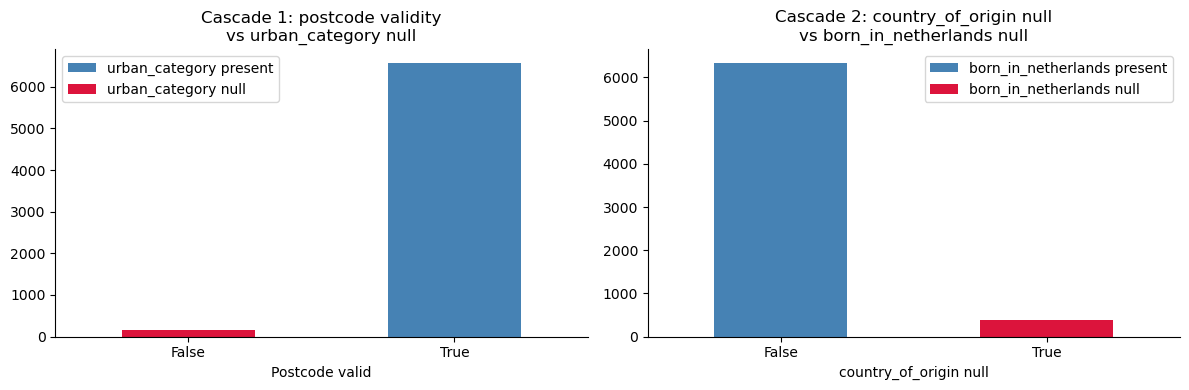

In [16]:
## Visualise cascades
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Cascade 1
cat1 = train_debtor.groupby('postcode_valid')['urban_null'].value_counts().unstack(fill_value=0)
cat1.plot(kind='bar', stacked=True, ax=axes[0], color=['steelblue','crimson'],
          legend=True)
axes[0].set_title('Cascade 1: postcode validity\nvs urban_category null')
axes[0].set_xlabel('Postcode valid')
# Label ticks from the actual categories present, rather than a hardcoded
# pair, since one side of the cascade can be empty depending on the data
axes[0].set_xticklabels([str(v) for v in cat1.index], rotation=0)
axes[0].legend(['urban_category present', 'urban_category null'])

# Cascade 2
cat2 = train_debtor.groupby('origin_null')['born_null'].value_counts().unstack(fill_value=0)
cat2.plot(kind='bar', stacked=True, ax=axes[1], color=['steelblue','crimson'])
axes[1].set_title('Cascade 2: country_of_origin null\nvs born_in_netherlands null')
axes[1].set_xlabel('country_of_origin null')
axes[1].set_xticklabels([str(v) for v in cat2.index], rotation=0)
axes[1].legend(['born_in_netherlands present', 'born_in_netherlands null'])

plt.tight_layout()
plt.show()

**QUESTION:** Why does it make no sense to impute `born_in_netherlands` independently
from `country_of_origin`? What would you do if both are missing for a debtor?

## Section 5: Data quality issues (train only)

Real agency data is messy. The dataset contains several categories of data quality
issues that a data scientist must detect before modelling. We work through each
systematically, documenting what we find and why it matters.

### 5.1 Malformed dates

Two types of malformed dates exist in `account_default_date`:
- `'00-00-0000'`: placeholder from a legacy system
- US date format (`mm/dd/yyyy`): affects ~5% of utility accounts imported from 
  a client system that used US date formatting

The US format is particularly dangerous: for dates where day ≤ 12, the format is
**ambiguous** (e.g. `01/06/2022` could be January 6 or June 1).

Malformed date value counts (train):
Series([], Name: count, dtype: int64)

US-format dates in utility accounts: 0 (0.0% of utility accounts)


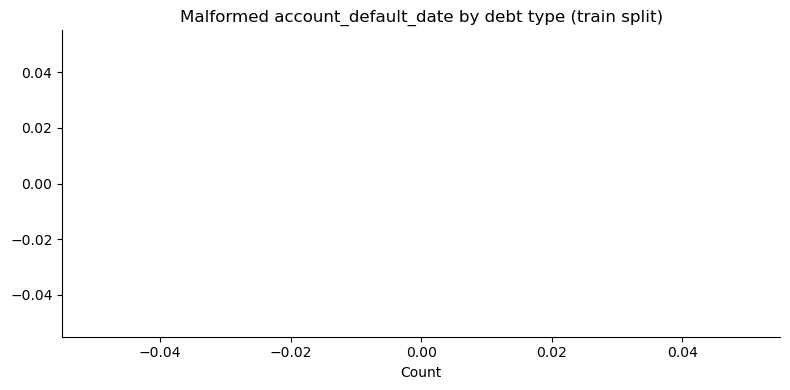

In [17]:
## Malformed date detection

# Extract original raw date strings where the date parsing failed (returned NaT)
bad_dates = train_acc[train_acc['default_date_parsed'].isna()]['account_default_date']

# Print header text for malformed date output
print('Malformed date value counts (train):')

# Print the top 10 most frequent raw values that caused parsing errors
print(bad_dates.value_counts().head(10))

# US format in utility accounts

# Define specific utility account debt type descriptions to flag
util_types = ['Electricity arrears', 'Gas arrears', 'Water arrears']

# Filter for rows belonging to utility types where the date parsed successfully
util_mask = train_acc['debt_type'].isin(util_types) & train_acc['default_date_parsed'].notna()

# Check if raw strings match MM/DD/YYYY format via regular expressions
us_format = train_acc[util_mask]['account_default_date'].str.match(r'^\d{2}/\d{2}/\d{4}$', na=False)

# Print out count and percentage summary of US-formatted dates found
print(f'\nUS-format dates in utility accounts: {us_format.sum()} '
      f'({us_format.mean()*100:.1f}% of utility accounts)')


# Visualise
fig, ax = plt.subplots(figsize=(8, 4))
bad_by_type = (train_acc[train_acc['default_date_parsed'].isna()]
               .groupby('debt_type').size().sort_values(ascending=False))
ax.barh(bad_by_type.index[::-1], bad_by_type.values[::-1], color='crimson')
ax.set_title('Malformed account_default_date by debt type (train split)')
ax.set_xlabel('Count')
plt.tight_layout()
plt.show()


**QUESTION:** For the US-format dates where the day is 12 or below, the date is genuinely ambiguous, so we set the parsed date to NaT rather than guessing. What is the argument for, and against, guessing dd/mm as a default instead?

### 5.2 Outlier detection: amount_paid and outstanding_balance

**Theory: IQR method**

The interquartile range (IQR) method flags values beyond $Q3 + k \cdot IQR$ or
below $Q1 - k \cdot IQR$ as outliers. We use $k = 3$ for extreme outliers
(transcription errors rather than legitimate high values).

$$\text{IQR} = Q3 - Q1$$
$$\text{upper bound} = Q3 + 3 \cdot \text{IQR}$$

**Theory: Z-score method**

$$z = \frac{x - \mu}{\sigma}$$

Values with $|z| > 5$ are flagged. For `amount_paid`, a Z-score above 5 is almost 
certainly a transcription error (an extra zero added by the agent).

Documentation: [scipy.stats.zscore](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.zscore.html)

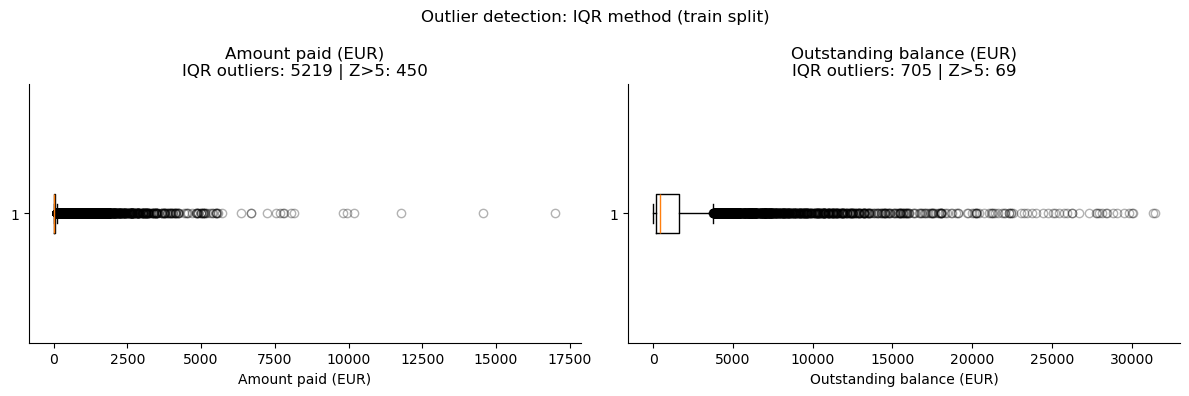

In [18]:
## IQR outlier detection

def flag_outliers_iqr(series, k=3):
    """Flags outliers using the Interquartile Range (IQR) method and calculates thresholds.

    Args:
        series (pd.Series): The numeric data column to evaluate for outliers.
        k (int or float, optional): The multiplier for the IQR range. Default is 3.

    Returns:
        tuple: A tuple containing three elements:
            - pd.Series (bool): Boolean mask where True indicates an outlier.
            - float: The calculated lower bound threshold.
            - float: The calculated upper bound threshold.
    """
    # Calculate the 25th (Q1) and 75th (Q3) percentiles of the data
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    # Compute the Interquartile Range
    iqr = q3 - q1
    # Determine extreme outlier boundary thresholds
    upper = q3 + k * iqr
    lower = q1 - k * iqr
    # Return boolean mask of violations alongside the threshold bounds
    return (series > upper) | (series < lower), lower, upper

# Initialize a grid of 1 row and 2 columns for side-by-side subplot visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loop through the target dataframes and numeric metrics to generate subplots
for i, (df, col, label) in enumerate([
    (train_tx, 'amount_paid', 'Amount paid (EUR)'),
    (train_acc, 'outstanding_balance', 'Outstanding balance (EUR)')]):

    # Drop missing values and extract IQR outlier details using the helper function
    outlier_mask, lo, hi = flag_outliers_iqr(df[col].dropna())
    # Calculate absolute Z-scores for comparison purposes
    z_scores = np.abs(stats.zscore(df[col].dropna()))

    # Draw a horizontal boxplot with specific visual styles applied to the flier marks
    axes[i].boxplot(df[col].dropna(), vert=False, flierprops={'marker':'o', 'color':'crimson', 'alpha':0.3})
    # Set subplot titles displaying both total IQR violations and extreme Z-score exceptions
    axes[i].set_title(f'{label}\nIQR outliers: {outlier_mask.sum()} | Z>5: {(z_scores>5).sum()}')
    # Add horizontal label names below the x-axis lines
    axes[i].set_xlabel(label)

# Plot
plt.suptitle('Outlier detection: IQR method (train split)', fontsize=12)
plt.tight_layout()
plt.show()


**QUESTION**: Why do we look at outliers?

An outlier count on its own doesn't tell us whether a flagged amount_paid value is a genuine data quality problem or just a large but legitimate payment. 
-  A €50,000 payment is an IQR outlier in isolation, but it's unremarkable if it's paying off a €50,000 debt. To tell these apart, we plot each flagged payment against its account's `original_amount`: a point sitting well above the `amount_paid` = `original_amount` line means someone was recorded as paying more in a single transaction than the entire debt was ever worth, which is the clearest visual signature of the transcription errors documented in the dataset specification (an extra zero added by the agent). 
- A flagged point that stays close to or below the diagonal is most likely just a large but genuine payment, not an error worth cleaning.

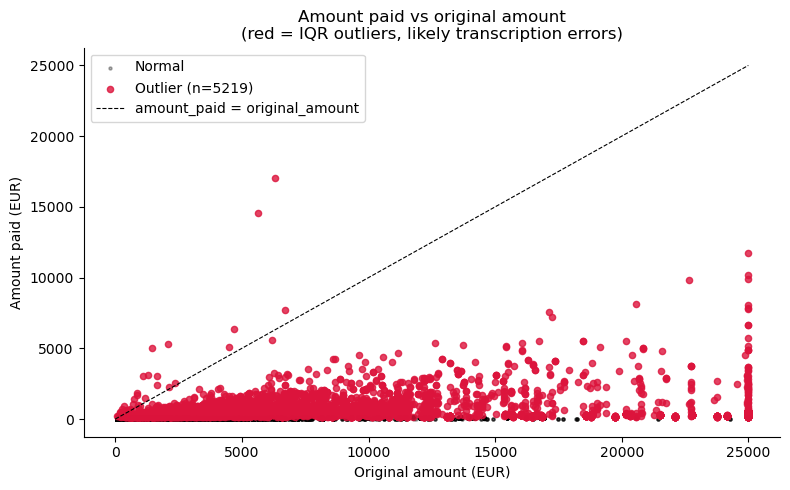

In [19]:
# Scatter: amount_paid vs original_amount (outliers highlighted)

# Merge original account amount fields into the transaction data using the common account ID key
sample_tx = train_tx.merge(train_acc[['account_id','original_amount']], on='account_id', how='left')

# Drop null values and identify payment amount outliers alongside their upper threshold bounds via the IQR function
outlier_mask, _, upper_amt = flag_outliers_iqr(sample_tx['amount_paid'].dropna())


fig, ax = plt.subplots(figsize=(8, 5))
normal = sample_tx[sample_tx['amount_paid'] <= upper_amt]
outlier = sample_tx[sample_tx['amount_paid'] > upper_amt]
ax.scatter(normal['original_amount'], normal['amount_paid'],
           alpha=0.3, s=5, color='black', label='Normal')
ax.scatter(outlier['original_amount'], outlier['amount_paid'],
           alpha=0.8, s=20, color='crimson', label=f'Outlier (n={len(outlier)})')
ax.plot([0, normal['original_amount'].max()], [0, normal['original_amount'].max()],
        'k--', linewidth=0.8, label='amount_paid = original_amount')
ax.set_xlabel('Original amount (EUR)')
ax.set_ylabel('Amount paid (EUR)')
ax.set_title('Amount paid vs original amount\n(red = IQR outliers, likely transcription errors)')
ax.legend()
plt.tight_layout()
plt.show()

**QUESTION:** What do you conclude from the graph above?

### 5.3 Outstanding balance > original amount

By definition, `outstanding_balance` should not exceed `original_amount` unless
interest has accrued. However, some percentage of the accounts have `outstanding_balance > 1.5 × original_amount`,
which is an interest capitalisation error in the source system.

Accounts where outstanding_balance > original_amount: 1624 (18.1%)
Accounts where outstanding_balance > 1.5 × original_amount: 5 (0.1%)


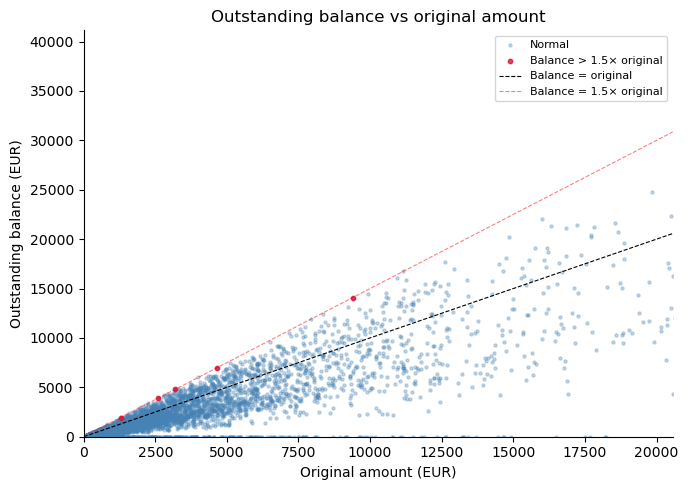

In [20]:
## Balance > original check

# Isolate accounts where the outstanding balance exceeds the original debt amount
balance_issue = train_acc[train_acc['outstanding_balance'] > train_acc['original_amount']]
# Print the count and percentage of accounts violating this baseline constraint
print(f'Accounts where outstanding_balance > original_amount: {len(balance_issue)} '
      f'({len(balance_issue)/len(train_acc)*100:.1f}%)')

# Isolate severe anomalies where the outstanding balance exceeds the original debt by more than 50%
extreme = train_acc[train_acc['outstanding_balance'] > 1.5 * train_acc['original_amount']]
# Print the count and percentage of accounts exhibiting extreme balance inflation
print(f'Accounts where outstanding_balance > 1.5 × original_amount: {len(extreme)} '
      f'({len(extreme)/len(train_acc)*100:.1f}%)')


fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(train_acc['original_amount'], train_acc['outstanding_balance'],
           alpha=0.3, s=5, color='steelblue', label='Normal')
ax.scatter(extreme['original_amount'], extreme['outstanding_balance'],
           alpha=0.8, s=10, color='crimson', label='Balance > 1.5× original')
max_val = train_acc['original_amount'].quantile(0.99)
ax.plot([0, max_val], [0, max_val], 'k--', linewidth=0.8, label='Balance = original')
ax.plot([0, max_val], [0, max_val*1.5], 'r--', linewidth=0.8, alpha=0.5, label='Balance = 1.5× original')
ax.set_xlim(0, max_val)
ax.set_ylim(0, max_val * 2)
ax.set_xlabel('Original amount (EUR)')
ax.set_ylabel('Outstanding balance (EUR)')
ax.set_title('Outstanding balance vs original amount')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 5.4 Duplicate rows

In [21]:
# Detect exact duplicates (excluding primary key columns)
tx_pk = 'transaction_id'
ch_pk = 'contact_id'

tx_dup_cols = [c for c in train_tx.columns if c not in [tx_pk, 'split']]
ch_dup_cols = [c for c in train_ch.columns if c not in [ch_pk, 'split']]

tx_dups = train_tx[train_tx.duplicated(subset=tx_dup_cols, keep=False)]
ch_dups = train_ch[train_ch.duplicated(subset=ch_dup_cols, keep=False)]

print(f'Duplicate rows in payment_transactions: {len(tx_dups)} ({len(tx_dups)/len(train_tx)*100:.2f}%)')
print(f'Duplicate rows in contact_history:      {len(ch_dups)} ({len(ch_dups)/len(train_ch)*100:.2f}%)')

if len(tx_dups) > 0:
    print('\nExample duplicate payment transaction pair:')
    example_acc = tx_dups.groupby(tx_dup_cols).filter(lambda x: len(x) >= 2).head(2)
    display(example_acc[['account_id','transaction_date','amount_paid','payment_method','channel']].head(2))

Duplicate rows in payment_transactions: 4 (0.01%)
Duplicate rows in contact_history:      0 (0.00%)

Example duplicate payment transaction pair:


,account_id,transaction_date,amount_paid,payment_method,channel


**QUESTION:** We drop duplicate rows, keeping the first occurrence. Could two genuinely different real-world payments end up looking like exact duplicates under this definition? What would you check to be more confident before dropping a row?

### 5.5 ANOVA: do key variables differ significantly across groups?

**Theory: One-way ANOVA**

ANOVA (Analysis of Variance) tests whether the means of a continuous variable
differ significantly across $k$ groups:
- $H_0$: $\mu_1 = \mu_2 = \cdots = \mu_k$ (all group means are equal)
- $H_1$: at least one group mean differs

$$F = \frac{\text{variance between groups}}{\text{variance within groups}}$$

When ANOVA is significant, **Tukey's HSD** post-hoc test identifies *which*
groups differ from each other.

Documentation: [scipy.stats.f_oneway](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html)  
Documentation: [statsmodels pairwise_tukeyhsd](https://www.statsmodels.org/stable/generated/statsmodels.stats.multicomp.pairwise_tukeyhsd.html)

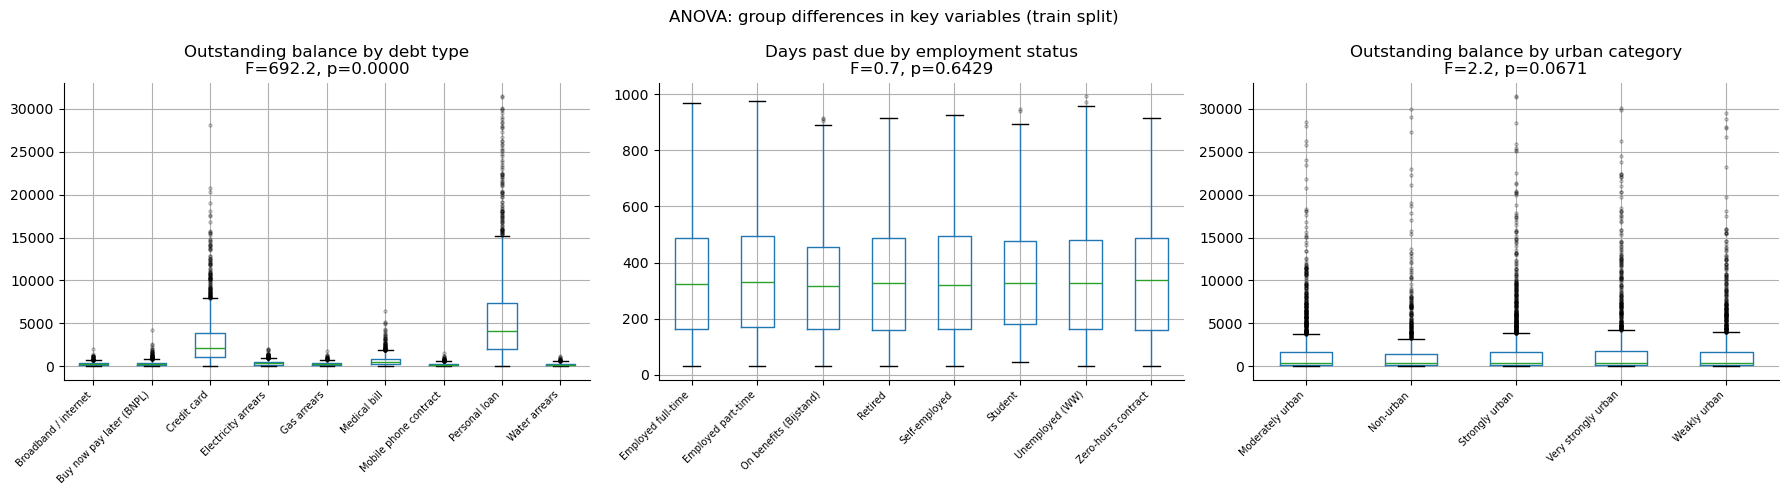


Tukey HSD for Outstanding balance by debt type (significant at p<0.05):
                      Multiple Comparison of Means - Tukey HSD, FWER=0.05                       
         group1                   group2           meandiff  p-adj    lower      upper    reject
------------------------------------------------------------------------------------------------
    Broadband / internet Buy now pay later (BNPL)    34.2506    1.0  -326.8846   395.3857  False
    Broadband / internet              Credit card  2741.2426    0.0   2413.527  3068.9581   True
    Broadband / internet      Electricity arrears   112.5555 0.9906  -258.6867   483.7977  False
    Broadband / internet              Gas arrears    19.6288    1.0  -380.5752   419.8327  False
    Broadband / internet             Medical bill   414.1736 0.0096    57.5253   770.8218   True
    Broadband / internet    Mobile phone contract   -49.7554    1.0  -442.4454   342.9345  False
    Broadband / internet            Personal loan  538

In [22]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

anova_tests = [
    (train_acc, 'outstanding_balance', 'debt_type',          'Outstanding balance by debt type'),
    (train_acc.merge(train_debtor[['debtor_id','employment_status']], on='debtor_id', how='left'),
                'days_past_due',       'employment_status',   'Days past due by employment status'),
    (train_acc.merge(train_debtor[['debtor_id','urban_category']], on='debtor_id', how='left'),
                'outstanding_balance', 'urban_category',      'Outstanding balance by urban category'),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (df, target_col, group_col, title) in enumerate(anova_tests):
    df_clean = df[[target_col, group_col]].dropna()
    groups = [grp[target_col].values for _, grp in df_clean.groupby(group_col)]
    f_stat, p_val = stats.f_oneway(*groups)

    df_clean.boxplot(column=target_col, by=group_col, ax=axes[i], vert=True,
                    flierprops={'marker':'o','markersize':2,'alpha':0.3})
    axes[i].set_title(f'{title}\nF={f_stat:.1f}, p={p_val:.4f}')
    axes[i].set_xlabel('')
    plt.setp(axes[i].get_xticklabels(), rotation=45, ha='right', fontsize=7)

plt.suptitle('ANOVA: group differences in key variables (train split)', fontsize=12)
plt.tight_layout()
plt.show()

# Tukey HSD for significant results
for df, target_col, group_col, title in anova_tests:
    df_clean = df[[target_col, group_col]].dropna()
    groups = [grp[target_col].values for _, grp in df_clean.groupby(group_col)]
    f_stat, p_val = stats.f_oneway(*groups)
    if p_val < 0.05:
        print(f'\nTukey HSD for {title} (significant at p<0.05):')
        tukey = pairwise_tukeyhsd(df_clean[target_col], df_clean[group_col])
        print(tukey.summary())

**QUESTION:** The ANOVA for `outstanding_balance` by `urban_category` comes out borderline (p ≈ 0.064, just above the conventional 0.05 threshold), while `debt_type` is clearly significant. 
- Does a borderline p-value mean there's no real relationship between urban category and outstanding balance, or could something about the test itself, sample size, number of groups, or how unevenly sized those groups are, explain why it didn't clear the threshold? 
- What would you check next?

Tukey HSD: outstanding_balance by urban_category
               Multiple Comparison of Means - Tukey HSD, FWER=0.05                
       group1              group2        meandiff p-adj    lower    upper   reject
----------------------------------------------------------------------------------
   Moderately urban           Non-urban    2.5642    1.0 -336.3189 341.4472  False
   Moderately urban      Strongly urban  141.3912 0.6259 -133.6122 416.3947  False
   Moderately urban Very strongly urban  288.2471 0.0555   -4.0945 580.5888  False
   Moderately urban        Weakly urban  144.1914 0.6758 -152.7935 441.1762  False
          Non-urban      Strongly urban  138.8271  0.796 -199.3459    477.0  False
          Non-urban Very strongly urban   285.683 0.1753   -66.734 638.0999  False
          Non-urban        Weakly urban  141.6272 0.8146 -214.6508 497.9053  False
     Strongly urban Very strongly urban  146.8559 0.6441 -144.6623 438.3741  False
     Strongly urban        Weakly urba

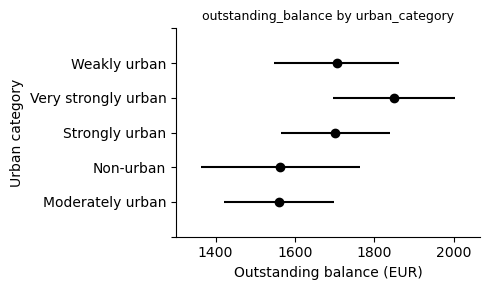

In [23]:
# Tukey HSD for outstanding_balance by urban_category, run regardless of the
# ANOVA p-value, so we can see whether any specific pair of urban categories
# differs even though the overall test was borderline (p ~ 0.064)

# Rebuild the same merged frame used in the ANOVA test above
urban_df = train_acc.merge(train_debtor[['debtor_id', 'urban_category']],
                            on='debtor_id', how='left')
urban_df_clean = urban_df[['outstanding_balance', 'urban_category']].dropna()

# Pairwise comparison of every urban_category level against every other
tukey_urban = pairwise_tukeyhsd(urban_df_clean['outstanding_balance'],
                                 urban_df_clean['urban_category'])
print('Tukey HSD: outstanding_balance by urban_category')
print(tukey_urban.summary())

# Visualise each pair's mean difference and confidence interval; 
# A pair whose interval crosses zero is not distinguishable at this significance level
fig, ax = plt.subplots()
tukey_urban.plot_simultaneous(ax=ax, figsize=(5, 3))
ax.set_title('outstanding_balance by urban_category', fontsize=9)
ax.set_xlabel('Outstanding balance (EUR)')
ax.set_ylabel('Urban category')
plt.tight_layout()
plt.show()

**QUESTION:** The omnibus ANOVA and the Tukey pairwise tests agree here, neither finds a statistically significant difference in `outstanding_balance` across `urban_category` groups, yet the largest pairwise gap (`Very strongly urban` vs `Moderately urban`) comes close, at p ≈ 0.056. What could you change about the test itself, not the underlying data, to give it a better chance of detecting a real effect if one exists? Consider the within-group variance, the number of groups being compared, and the scale the variable is measured on.

## Section 6: Cleaning decisions (fit on train, apply to all)

We document each cleaning decision with its justification.
All decisions are based on the training set only, then applied consistently
to train, val, and test.

| Issue | Decision | Justification |
|---|---|---|
| `account_default_date = '00-00-0000'` | Set to NaT, flag column | Unrecoverable placeholder |
| US format dates in utility accounts | Convert where day > 12 (unambiguous); set ambiguous to NaT | Cannot distinguish Jan 6 from Jun 1 when day ≤ 12 |
| Malformed postcodes ('????', 'XXXX') | Set to NaN; cascade to urban_category = NaN | Unrecoverable; urban_category derived from postcode |
| Duplicate rows | Drop keeping first occurrence | Same-day same-amount entries are data entry errors |
| `amount_paid` IQR outliers | Cap at Q3 + 3×IQR; flag column | Likely transcription errors; capping preferred to dropping |
| `outstanding_balance > 1.5 × original_amount` | Cap at 1.5×; flag column | Interest capitalisation error; 1.5× is a reasonable ceiling |
| `transaction_date < account_default_date` | Flag as `date_inconsistency = True`; do not drop | Cross-file inconsistency; keep for analysis, exclude from target window |

In [24]:
# Apply cleaning to all splits

def clean_accounts(df):
    """Cleans the accounts table: flags and fixes malformed default dates.

    Args:
        df (pd.DataFrame): Raw or partially processed accounts table. Must
            already contain 'default_date_parsed' (from pd.to_datetime with
            errors='coerce') and the original 'account_default_date' string
            column.

    Returns:
        pd.DataFrame: A copy of df with 'default_date_imputed' added and
            unambiguous US-format dates (day > 12) converted in place.
    """
    # Work on a copy so the caller's original DataFrame is never mutated
    df = df.copy()

    # Flag every row where date parsing failed (placeholder '00-00-0000' or
    # a genuinely malformed string) so we can track how much data this affects
    df['default_date_imputed'] = df['default_date_parsed'].isna()

    # Identify raw strings that match the US mm/dd/yyyy pattern
    us_mask = df['account_default_date'].str.match(r'^\d{2}/\d{2}/\d{4}$', na=False)

    def convert_us_date(d):
        """Converts one US-format date string to a Timestamp if unambiguous.

        Args:
            d (str): A date string already known to match mm/dd/yyyy.

        Returns:
            pd.Timestamp or pd.NaT: The parsed date if day > 12 (so it
                cannot be confused with a European dd/mm date), else NaT.
        """
        # Split the string into its month, day, year components
        parts = d.split('/')
        if len(parts) == 3:
            month, day, year = parts
            # Only convert when the day component could not also be a month
            # (day > 12), otherwise the format is genuinely ambiguous
            if int(day) > 12:
                return pd.Timestamp(f'{year}-{month}-{day}')
        # Ambiguous or malformed: leave as missing rather than guess
        return pd.NaT

    # Apply the conversion only to the rows flagged as US-format, overwriting
    # their previously-NaT parsed date with the corrected Timestamp
    df.loc[us_mask, 'default_date_parsed'] = (
        df.loc[us_mask, 'account_default_date'].apply(convert_us_date))

    return df


def clean_debtors(df):
    """Cleans the debtor_profiles table: fixes postcodes and cascading nulls.

    Args:
        df (pd.DataFrame): Raw or partially processed debtor_profiles table.
            Must contain 'postcode', 'urban_category', 'country_of_origin',
            and 'born_in_netherlands'.

    Returns:
        pd.DataFrame: A copy of df with malformed postcodes set to NaN, the
            postcode -> urban_category cascade enforced, and the
            country_of_origin -> born_in_netherlands cascade enforced.
    """
    df = df.copy()

    def is_valid_pc(pc):
        """Checks whether a postcode value is a valid 4-digit Dutch code.

        Args:
            pc: The raw postcode value (may be NaN, a string, or a number).

        Returns:
            bool: True if pc is a 4-character all-digit string, else False.
        """
        # Missing values are never valid
        if pd.isna(pc):
            return False
        # Strip whitespace and check it is exactly 4 digits
        s = str(pc).strip()
        return len(s) == 4 and s.isdigit()

    # Flag every row whose postcode fails the validity check
    df['postcode_malformed'] = ~df['postcode'].apply(is_valid_pc)
    # Overwrite malformed postcodes with NaN so downstream code treats them
    # as genuinely missing rather than as a valid-looking placeholder string
    df.loc[df['postcode_malformed'], 'postcode'] = np.nan

    # Structural cascade 1: urban_category can only ever be known if postcode
    # is known, so force it to null wherever postcode is null
    df.loc[df['postcode'].isna(), 'urban_category'] = np.nan

    # Structural cascade 2: born_in_netherlands can only ever be known if
    # country_of_origin is known, so force it to null wherever origin is null.
    # astype(object) first guards against a native bool dtype, which cannot
    # hold NaN, if the column happened to load with no existing nulls.
    df['born_in_netherlands'] = (
        df['born_in_netherlands'].astype(object).where(df['country_of_origin'].notna()))

    return df


def clean_transactions(df, acc_df_clean):
    """Cleans payment_transactions: drops duplicates, caps outliers, flags
    cross-file date inconsistencies.

    Args:
        df (pd.DataFrame): Raw payment_transactions table.
        acc_df_clean (pd.DataFrame): The already-cleaned accounts table,
            used to look up each account's default date for the
            cross-file consistency check.

    Returns:
        pd.DataFrame: A copy of df, deduplicated, with 'amount_capped' and
            'date_inconsistency' flag columns added and 'amount_paid'
            clipped at its IQR-based upper bound.
    """
    df = df.copy()

    # Drop exact duplicate rows, ignoring the primary key and split columns
    # (two rows that agree on every business column are the same event
    # logged twice, not two coincidentally identical payments)
    pk = 'transaction_id'
    dup_cols = [c for c in df.columns if c not in [pk, 'split']]
    df = df.drop_duplicates(subset=dup_cols, keep='first')

    # Compute the IQR-based upper bound for amount_paid (k=3, matching the
    # extreme-outlier threshold used in the Section 5.2 exploration)
    q3 = df['amount_paid'].quantile(0.75)
    iqr = df['amount_paid'].quantile(0.75) - df['amount_paid'].quantile(0.25)
    cap = q3 + 3 * iqr

    # Flag which rows were affected by capping before overwriting the values,
    # so the effect of this decision stays auditable downstream
    df['amount_capped'] = df['amount_paid'] > cap
    df['amount_paid'] = df['amount_paid'].clip(upper=cap)

    # Look up each transaction's account default date from the cleaned
    # accounts table, so we can check for cross-file date inconsistencies
    date_map = acc_df_clean.set_index('account_id')['default_date_parsed'].to_dict()
    df['default_date'] = df['account_id'].map(date_map)
    df['tx_date_parsed'] = pd.to_datetime(df['transaction_date'], errors='coerce')

    # A transaction that happened before the account even defaulted is a
    # logical inconsistency between files; flag it rather than silently drop it
    df['date_inconsistency'] = df['tx_date_parsed'] < df['default_date']

    return df


def clean_contacts(df):
    """Cleans contact_history_enriched: drops duplicates, fixes invalid times.

    Args:
        df (pd.DataFrame): Raw contact_history_enriched table.

    Returns:
        pd.DataFrame: A copy of df, deduplicated, with 'contact_time_invalid'
            flagged and implausible contact_time values set to NaN.
    """
    df = df.copy()

    # Drop exact duplicate rows, ignoring the primary key and split columns
    pk = 'contact_id'
    dup_cols = [c for c in df.columns if c not in [pk, 'split']]
    df = df.drop_duplicates(subset=dup_cols, keep='first')

    def valid_time(t):
        """Checks whether a contact_time string is a plausible HH:MM time.

        Args:
            t: The raw contact_time value (may be NaN or an 'HH:MM' string).

        Returns:
            bool: True if t is missing (nothing to validate) or parses to
                an hour in [0, 23] and a minute in [0, 59], else False.
        """
        # Missing values pass through untouched; they are not "invalid",
        # they are simply absent
        if pd.isna(t):
            return True
        try:
            h, m = str(t).split(':')
            return 0 <= int(h) <= 23 and 0 <= int(m) <= 59
        except:
            # Anything that doesn't even parse as HH:MM is invalid
            return False

    # Flag every row whose contact_time fails the plausibility check
    # (this catches the known '25:00' system bug)
    df['contact_time_invalid'] = ~df['contact_time'].apply(valid_time)
    # Overwrite invalid times with NaN rather than guessing a correction
    df.loc[df['contact_time_invalid'], 'contact_time'] = np.nan

    return df


# Apply every cleaning function to its table. Each function was designed
# against train_acc / train_debtor / train_tx / train_ch above, but is now
# applied to the FULL table (all splits) using the same fixed logic, since
# none of these rules used any train-only statistic that could leak
# information from val/test.
acc_clean    = clean_accounts(acc_df)
debtor_clean = clean_debtors(debtor_df)
tx_clean     = clean_transactions(tx_df, acc_clean)
ch_clean     = clean_contacts(ch_df)

# Outstanding balance cap: applied separately here because it depends on
# each row's own original_amount rather than a single global threshold
acc_clean['balance_capped'] = acc_clean['outstanding_balance'] > 1.5 * acc_clean['original_amount']
acc_clean['outstanding_balance'] = acc_clean.apply(
    lambda r: min(r['outstanding_balance'], r['original_amount'] * 1.5), axis=1)

print('Cleaning complete.')
print(f'  Transactions after dedup: {len(tx_clean):,} (removed {len(tx_df)-len(tx_clean):,} duplicates)')
print(f'  Contacts after dedup:     {len(ch_clean):,} (removed {len(ch_df)-len(ch_clean):,} duplicates)')
print(f'  Amount_paid capped:       {tx_clean["amount_capped"].sum():,} rows')
print(f'  Balance capped:           {acc_clean["balance_capped"].sum():,} rows')
print(f'  Date inconsistencies:     {tx_clean["date_inconsistency"].sum():,} rows')

Cleaning complete.
  Transactions after dedup: 87,491 (removed 2 duplicates)
  Contacts after dedup:     111,251 (removed 0 duplicates)
  Amount_paid capped:       7,320 rows
  Balance capped:           9 rows
  Date inconsistencies:     1,031 rows


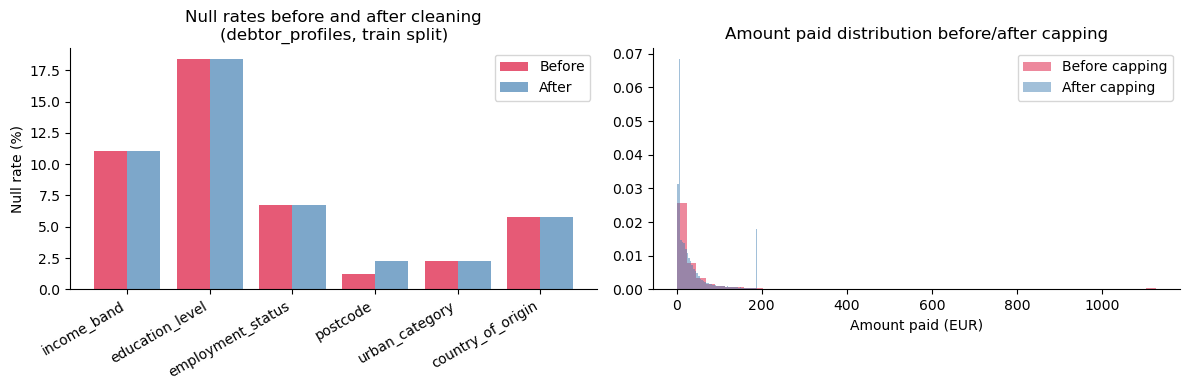

In [25]:
# Before/after null rates for key columns
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Columns to compare before vs after the Section 6 cleaning pass
cols_to_check = ['income_band', 'education_level', 'employment_status',
                 'postcode', 'urban_category', 'country_of_origin']

# Null rate on the train split BEFORE cleaning, using the original raw tables
before_rates = [debtor_df[debtor_df['debtor_id'].isin(
    debtor_df[debtor_df['split']=='train']['debtor_id'])][c].isna().mean()*100
    if c in debtor_df.columns else 0 for c in cols_to_check]

# Null rate on the train split AFTER cleaning, using the cleaned tables
after_rates  = [debtor_clean[debtor_clean['split']=='train'][c].isna().mean()*100
    if c in debtor_clean.columns else 0 for c in cols_to_check]

# Left panel: grouped bar chart, before vs after, per column
x = range(len(cols_to_check))
axes[0].bar([i-0.2 for i in x], before_rates, 0.4, label='Before', color='crimson', alpha=0.7)
axes[0].bar([i+0.2 for i in x], after_rates,  0.4, label='After',  color='steelblue', alpha=0.7)
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(cols_to_check, rotation=30, ha='right')
axes[0].set_ylabel('Null rate (%)')
axes[0].set_title('Null rates before and after cleaning\n(debtor_profiles, train split)')
axes[0].legend()

# Right panel: amount_paid distribution before/after IQR capping, train split
# only, clipped at the 99th percentile purely for plot readability (the
# capping itself already happened in clean_transactions above)
train_tx_before = tx_df[tx_df['split']=='train']['amount_paid'].dropna()
train_tx_after  = tx_clean[tx_clean['split']=='train']['amount_paid'].dropna()
axes[1].hist(train_tx_before.clip(upper=train_tx_before.quantile(0.99)),
             bins=50, alpha=0.5, color='crimson', label='Before capping', density=True)
axes[1].hist(train_tx_after.clip(upper=train_tx_after.quantile(0.99)),
             bins=50, alpha=0.5, color='steelblue', label='After capping', density=True)
axes[1].set_title('Amount paid distribution before/after capping')
axes[1].set_xlabel('Amount paid (EUR)')
axes[1].legend()

plt.tight_layout()
plt.show()

**QUESTION:** The null rate for some columns barely changed after cleaning. Is that expected? For each column here, which specific cleaning step, if any, was supposed to touch it?

## Section 7: Feature engineering (fit on train, apply to all)

Feature engineering converts the raw cleaned columns into numeric inputs suitable
for ML models. All transformations are **fitted on the training set only**
and applied to val and test without refitting.

### 7.1 Date-derived features

In [26]:
# age_at_default: (account_default_date - date_of_birth) in years

# Build a debtor_id -> date_of_birth lookup and map it onto every account
# (an account belongs to one debtor, but a debtor can have several accounts)
dob_map = debtor_clean.set_index('debtor_id')['date_of_birth'].to_dict()
acc_clean['date_of_birth'] = acc_clean['debtor_id'].map(dob_map)
acc_clean['dob_parsed']    = pd.to_datetime(acc_clean['date_of_birth'], errors='coerce')

# Age in years at the moment the account defaulted, using 365.25 days/year
# to account for leap years on average
acc_clean['age_at_default'] = (
    (acc_clean['default_date_parsed'] - acc_clean['dob_parsed']).dt.days / 365.25)


def postcode_to_city(pc):
    """Maps a Dutch 4-digit postcode to one of four major cities or 'Other'.

    Postcode ranges follow the known concentration of debtor postcodes in
    Rotterdam, Den Haag, Amsterdam and Utrecht used when the synthetic
    dataset was generated (see the dataset specification for the exact
    ranges and their poverty multipliers).

    Args:
        pc: The raw postcode value (may be NaN, a string, or a number).

    Returns:
        str or float: One of 'Rotterdam', 'Den Haag', 'Amsterdam',
            'Utrecht', 'Other', or np.nan if pc is missing or unparsable.
    """
    # Missing postcodes cannot be mapped to a city
    if pd.isna(pc):
        return np.nan
    try:
        # Cast to int so leading zeros and string formatting don't matter
        p = int(str(pc).strip())
        if 3000 <= p < 3090:
            return 'Rotterdam'
        if 2500 <= p < 2560:
            return 'Den Haag'
        if 1000 <= p < 1110:
            return 'Amsterdam'
        if 3500 <= p < 3560:
            return 'Utrecht'
        # Any valid postcode outside the four major ranges
        return 'Other'
    except:
        # Postcode string could not be parsed as an integer
        return np.nan


# Map each account's debtor's postcode onto the account, then derive city
postcode_map = debtor_clean.set_index('debtor_id')['postcode'].to_dict()
acc_clean['postcode'] = acc_clean['debtor_id'].map(postcode_map)
acc_clean['city'] = acc_clean['postcode'].apply(postcode_to_city)

# Seasonality features: month and year the account defaulted, useful for
# spotting seasonal effects (e.g. more BNPL defaults after the holidays)
acc_clean['default_month'] = acc_clean['default_date_parsed'].dt.month
acc_clean['default_year']  = acc_clean['default_date_parsed'].dt.year

print('Date features created:')
print(acc_clean[['age_at_default','city','default_month','default_year']].describe())

Date features created:
       age_at_default  default_month  default_year
count    13156.000000   13731.000000  13731.000000
mean        42.818327       6.165465   2021.801981
std         15.932231       3.432462      1.317775
min         13.240246       1.000000   2020.000000
25%         29.598905       3.000000   2021.000000
50%         42.043806       6.000000   2022.000000
75%         54.784394       9.000000   2023.000000
max         80.249144      12.000000   2024.000000


### 7.2 Normality tests and log transforms

Many ML models (linear and logistic regression in particular) perform better when continuous
features are approximately normally distributed. 

We test normality using the **Shapiro-Wilk test** on a sample, then apply a log transform where appropriate.

$$H_0: \text{the data is normally distributed}$$

For large samples we also use the **Kolmogorov-Smirnov test** against a normal distribution.

Documentation: [scipy.stats.shapiro](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html)  
Documentation: [scipy.stats.kstest](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kstest.html)

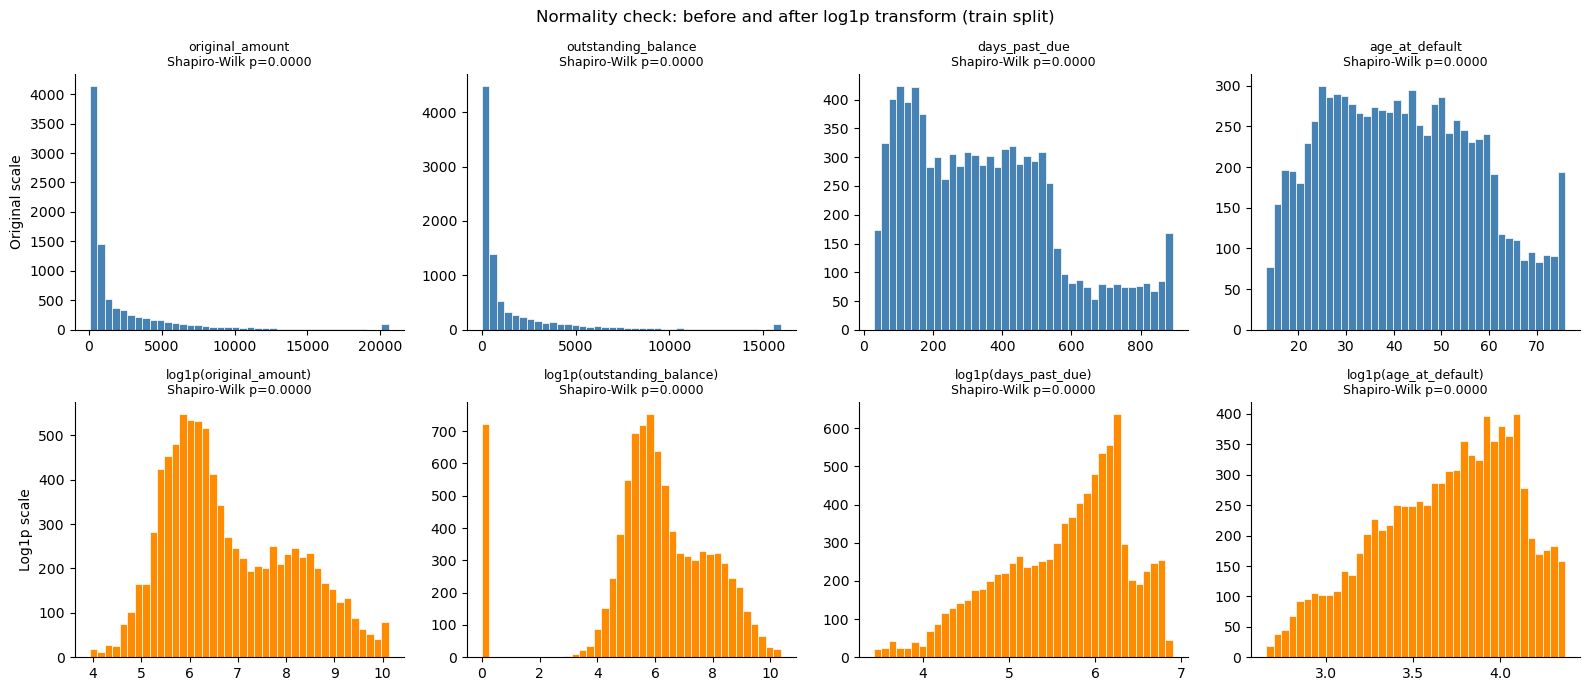

Decision: apply log1p to original_amount, outstanding_balance, days_past_due
(Shapiro-Wilk p-values confirm right-skew; log transform improves normality)


In [27]:
# Normality tests on train split
train_acc_clean = acc_clean[acc_clean['split'] == 'train'].copy()

# Continuous features we are considering for a log transform
cont_cols = ['original_amount', 'outstanding_balance', 'days_past_due', 'age_at_default']

fig, axes = plt.subplots(2, len(cont_cols), figsize=(16, 7))

for i, col in enumerate(cont_cols):
    # Drop missing values before testing or plotting
    data = train_acc_clean[col].dropna()
    # Shapiro-Wilk is only valid/fast on a modest sample size, so we subsample
    sample = data.sample(min(500, len(data)), random_state=42)

    # Shapiro-Wilk test on the original scale
    stat, p = stats.shapiro(sample)

    # Top row: histogram on the original scale (clipped at the 99th
    # percentile so a handful of extreme values don't flatten the plot)
    axes[0, i].hist(data.clip(upper=data.quantile(0.99)), bins=40,
                    color='steelblue', edgecolor='white', linewidth=0.5)
    axes[0, i].set_title(f'{col}\nShapiro-Wilk p={p:.4f}', fontsize=9)

    # Bottom row: histogram after a log1p transform, with its own
    # Shapiro-Wilk test to see whether normality actually improved
    log_data = np.log1p(data)
    log_sample = np.log1p(sample)
    stat_log, p_log = stats.shapiro(log_sample)
    axes[1, i].hist(log_data, bins=40, color='darkorange', edgecolor='white', linewidth=0.5)
    axes[1, i].set_title(f'log1p({col})\nShapiro-Wilk p={p_log:.4f}', fontsize=9)

axes[0, 0].set_ylabel('Original scale')
axes[1, 0].set_ylabel('Log1p scale')
plt.suptitle('Normality check: before and after log1p transform (train split)', fontsize=12)
plt.tight_layout()
plt.show()

print('Decision: apply log1p to original_amount, outstanding_balance, days_past_due')
print('(Shapiro-Wilk p-values confirm right-skew; log transform improves normality)')

**QUESTION:** age_at_default is not heavily skewed, yet the decision above still applies a log transform mainly to the other three columns. What is the risk of log-transforming a feature that is already close to normal, and how would you check whether it actually hurt?

**Why does the Shapiro-Wilk p-value stay near zero both before and after the log transform?**

With a few hundred observations, Shapiro-Wilk has enough power to detect even tiny departures from *exact* normality, and real financial data never satisfies that exactly, even after a transform that meaningfully reduces skew. So $p ≈ 0$ on both sides doesn't mean the transform failed, it means the test can't distinguish "barely non-normal" from "wildly non-normal." That's what the skewness comparison below is for.

**Skewness** measures how asymmetric a distribution is around its mean. For a perfectly symmetric distribution (like a true normal distribution), skewness equals 0. A positive value means the distribution has a long tail stretching to the right, a small number of very large values pulling the mean above the median, which is exactly the shape we'd expect from financial variables like `original_amount` or `outstanding_balance`, where most debts are modest but a few are very large. A negative value means the opposite, a long tail to the left.

$$\text{Skewness} = \frac{E[(X - \mu)^3]}{\sigma^3}$$

Unlike the Shapiro-Wilk test, which only returns a binary pass/fail on the null hypothesis of *exact* normality, skewness is a continuous measure, it tells you *how much* asymmetry there is, and lets you directly compare the distribution before and after a transform. As a rule of thumb: |skew| < 0.5 is considered approximately symmetric, 0.5-1 is moderately skewed, and above 1 is highly skewed. This makes it a more useful diagnostic than Shapiro-Wilk for judging whether a log transform actually helped, since Shapiro-Wilk can reject normality (p ≈ 0) both before and after a transform even when the transform meaningfully improved the shape of the distribution, a continuous skewness score will still show that improvement even when the significance test can't.

In [28]:
from scipy.stats import skew

for col in cont_cols:
    data = train_acc_clean[col].dropna()
    raw_skew = skew(data)
    log_skew = skew(np.log1p(data))
    print(f'{col:<20} raw skew={raw_skew:>7.2f}   log1p skew={log_skew:>7.2f}')

original_amount      raw skew=   3.22   log1p skew=   0.52
outstanding_balance  raw skew=   3.92   log1p skew=  -1.17
days_past_due        raw skew=   0.66   log1p skew=  -0.59
age_at_default       raw skew=   0.24   log1p skew=  -0.42


We observe from the skewness results: 
- `original_amount` and `outstanding_balance` improve substantially under the log transform (skew magnitude roughly halved or better), confirming they are worth transforming.
- `age_at_default` gets worse (0.24 → -0.42), confirming it is to be left untransformed. 
- `days_past_due` barely changes (0.66 → -0.59), just flipping sign, making it a weak case for the transform.

In [29]:
# Apply log transforms (train parameters, applied to all)
# NOTE: log1p needs no fitted parameters (unlike a scaler), so there is
# nothing here that could leak train-only information into val/test; the
# same fixed transform is simply applied to every row.
log_cols = ['original_amount', 'outstanding_balance', 'days_past_due']
for col in log_cols:
    # clip(lower=0) guards against any stray negative value reaching log1p,
    # which would otherwise raise or silently produce NaN
    acc_clean[f'log_{col}'] = np.log1p(acc_clean[col].clip(lower=0))

# train_acc_clean was copied from acc_clean BEFORE these log_ columns
# existed, so refresh it now, otherwise every downstream cell that filters
# train_acc_clean on a log_ column would raise a KeyError
train_acc_clean = acc_clean[acc_clean['split'] == 'train'].copy()

print('Log-transformed columns added:', [f'log_{c}' for c in log_cols])

Log-transformed columns added: ['log_original_amount', 'log_outstanding_balance', 'log_days_past_due']


### 7.3 Correlation analysis

We check associations between feature variables and with the target to inform
feature selection.

- **Pearson correlation**: continuous ↔ continuous, measures linear association
  - Assumes a straight-line relationship; sensitive to outliers and to the right-skew we saw in Section 7.2
- **Spearman correlation**: continuous ↔ continuous, measures monotonic association (not necessarily linear)
  - Ranks the values first, so it's robust to outliers and skew, useful as a check when Pearson looks weak
- **Cramér's V**: nominal ↔ nominal, measures strength of association (0=none, 1=perfect)
  - Built from the chi-squared statistic, rescaled so it's comparable across pairs with different numbers of categories
- **Kruskal-Wallis H test**: continuous ↔ nominal, non-parametric alternative to **ANOVA**
  - Tests whether the continuous variable's distribution differs across the nominal variable's groups, without assuming normality

Documentation: [pandas.DataFrame.corr](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)

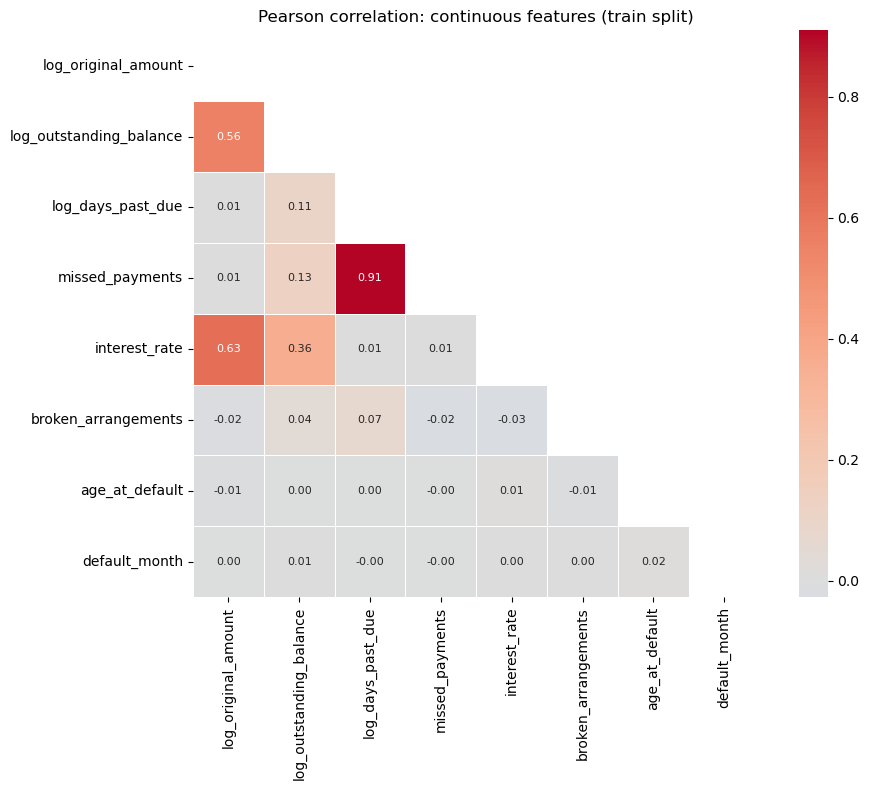

Pairs with |r| > 0.5 (potential multicollinearity):
  log_original_amount <-> log_outstanding_balance: r = 0.561
  log_days_past_due <-> missed_payments: r = 0.910
  interest_rate <-> log_original_amount: r = 0.625


In [30]:
# Pearson correlation heatmap for continuous features (train only)
cont_features = ['log_original_amount', 'log_outstanding_balance', 'log_days_past_due',
                 'missed_payments', 'interest_rate', 'broken_arrangements', 'age_at_default',
                 'default_month']

# Pearson correlation matrix, computed on the train split only
corr_matrix = train_acc_clean[cont_features].corr(method='pearson')

fig, ax = plt.subplots(figsize=(10, 8))
# Mask the upper triangle (including the diagonal) so each pair is shown once
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            mask=mask, ax=ax, square=True, linewidths=0.5,
            annot_kws={'size': 8})
ax.set_title('Pearson correlation: continuous features (train split)', fontsize=12)
plt.tight_layout()
plt.show()

# List any pair whose |correlation| exceeds 0.5, as an early multicollinearity
# warning ahead of the formal VIF check in Section 7.4
print('Pairs with |r| > 0.5 (potential multicollinearity):')
for col1 in cont_features:
    for col2 in cont_features:
        if col1 < col2:
            r = corr_matrix.loc[col1, col2]
            if abs(r) > 0.5:
                print(f'  {col1} <-> {col2}: r = {r:.3f}')

**QUESTION:** Pearson correlation only captures linear relationships. Name one pair of features here where a non-linear relationship could plausibly exist, and describe how you would test for it?

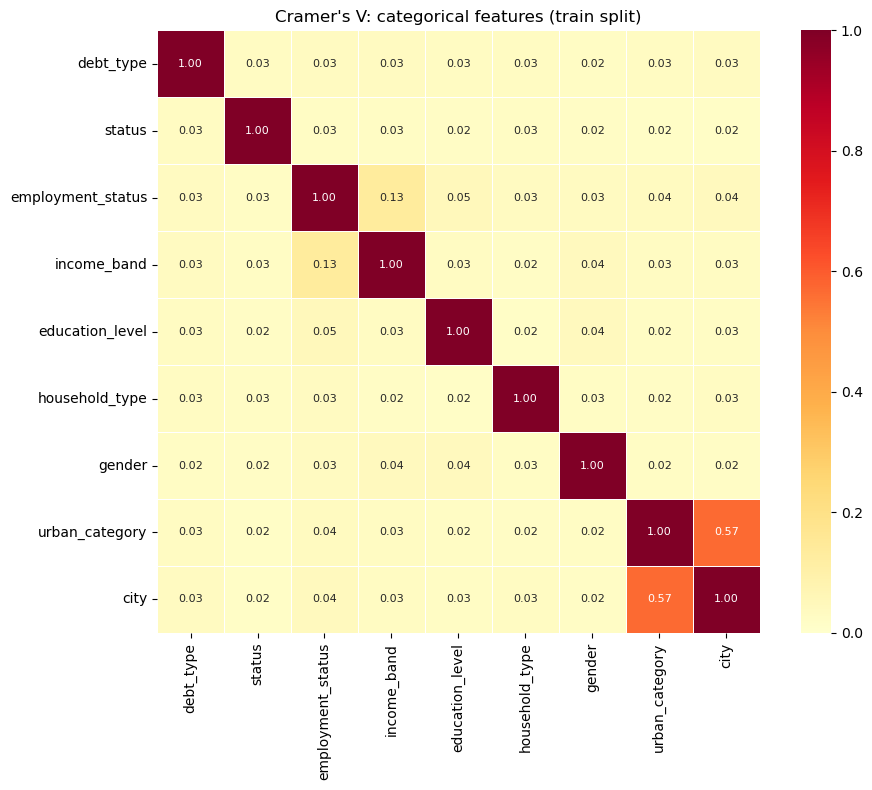

In [31]:
# Cramer's V for categorical features (train only)
def cramers_v(x, y):
    """Computes Cramer's V, the strength of association between two nominal variables.

    Cramer's V rescales the chi-squared statistic from a contingency table
    into a value between 0 (no association) and 1 (perfect association),
    which makes it comparable across variable pairs with different numbers
    of categories, unlike the raw chi-squared statistic.

    Args:
        x (pd.Series): First categorical variable.
        y (pd.Series): Second categorical variable, same length as x.

    Returns:
        float: Cramer's V, in [0, 1]. Returns 0 if the smaller dimension
            of the contingency table has only one category (dof=0).
    """
    # Build the contingency table between the two categorical variables
    ct = pd.crosstab(x, y)
    # Chi-squared statistic without Yates' continuity correction, to match
    # the standard Cramer's V formula
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.sum().sum()
    # Degrees of freedom is one less than the smaller table dimension
    dof = min(ct.shape) - 1
    return np.sqrt((chi2 / n) / dof) if dof > 0 else 0


# Join all categorical features onto the train accounts, so every pairwise
# combination can be computed from a single DataFrame
train_all = train_acc_clean.merge(
    debtor_clean[debtor_clean['split']=='train'][
        ['debtor_id','employment_status','income_band','education_level',
         'household_type','gender','country_of_origin','urban_category']],
    on='debtor_id', how='left')

cat_features = ['debt_type','status','employment_status','income_band',
                'education_level','household_type','gender','urban_category','city']
# Keep only the columns that actually exist after the merge (defensive,
# in case a column name changes upstream)
cat_features = [c for c in cat_features if c in train_all.columns]

# Build the full pairwise Cramer's V matrix
cv_matrix = pd.DataFrame(index=cat_features, columns=cat_features, dtype=float)
for c1 in cat_features:
    for c2 in cat_features:
        # Only compare rows where both variables are present
        mask = train_all[c1].notna() & train_all[c2].notna()
        cv_matrix.loc[c1, c2] = cramers_v(train_all.loc[mask, c1], train_all.loc[mask, c2])

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cv_matrix.astype(float), annot=True, fmt='.2f', cmap='YlOrRd',
            ax=ax, square=True, linewidths=0.5, annot_kws={'size': 8},
            vmin=0, vmax=1)
ax.set_title("Cramer's V: categorical features (train split)", fontsize=12)
plt.tight_layout()
plt.show()

#### 7.3b Feature relationships with the target (preview)

Before finalising which continuous features to carry into feature engineering, it helps to see how they relate to the outcome we actually care about. `repayment_probability` is not derived until Section 8, so here we compute a quick preview version, using only `payment_transactions` joined to `account_default_date`, purely to colour this plot. 
- Class 1 (orange): the debtor made at least one payment (amount_paid > 0) within 90 days of account_default_date.
- Class 0 (steelblue): the debtor made no such payment, either they paid nothing at all, or their only payments fell outside the 90-day window.

**NOTE**: The authoritative version, with the full 90-day window logic and date-inconsistency handling, is derived properly in Section 8.

Top continuous features by |correlation| with repayment_preview:
log_days_past_due         -0.450
missed_payments           -0.381
broken_arrangements       -0.163
log_outstanding_balance   -0.067


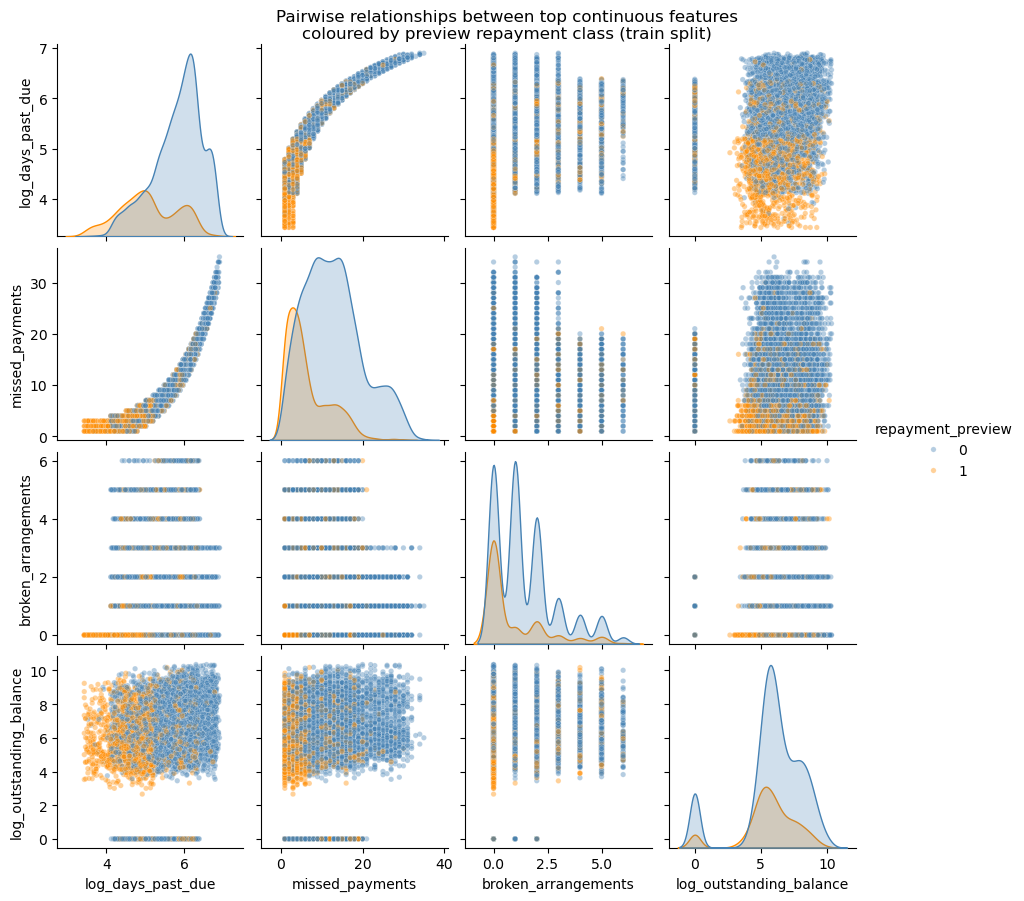

In [32]:
# Quick preview of the repayment target, computed here only to colour
# this exploratory plot (train split only, matching the EDA-on-train rule)
preview_tx = tx_clean.copy()
preview_tx['days_since_default'] = (
    preview_tx['tx_date_parsed'] - preview_tx['default_date']).dt.days
preview_90 = preview_tx[
    (preview_tx['days_since_default'] >= 0) &
    (preview_tx['days_since_default'] <= 90)]

# One row per account: 1 if any payment fell inside the 90-day window
repayment_preview_flag = (preview_90.groupby('account_id')['amount_paid']
                          .apply(lambda x: (x > 0).any()).astype(int))

# Attach the preview flag onto the train accounts used throughout Section 7
train_acc_clean['repayment_preview'] = (
    train_acc_clean['account_id'].map(repayment_preview_flag).fillna(0).astype(int))

# Rank continuous features by |correlation| with the preview target and
# keep the top four, so the pairplot stays readable
preview_corr = (train_acc_clean[cont_features + ['repayment_preview']]
               .corr()['repayment_preview'].drop('repayment_preview'))
top_features = preview_corr.abs().sort_values(ascending=False).head(4).index.tolist()
print('Top continuous features by |correlation| with repayment_preview:')
print(preview_corr[top_features].round(3).to_string())

# Pairplot: pairwise scatter plus a univariate KDE on the diagonal,
# coloured by the preview repayment class
pairplot_df = train_acc_clean[top_features + ['repayment_preview']].dropna()
g = sns.pairplot(pairplot_df, hue='repayment_preview', diag_kind='kde',
                  palette={0: 'steelblue', 1: 'darkorange'},
                  plot_kws={'alpha': 0.4, 's': 15}, height=2.2)
g.fig.suptitle('Pairwise relationships between top continuous features\n'
               'coloured by preview repayment class (train split)', y=1.02)
plt.show()

**QUESTION:** Look at the diagonal KDE panels above. For which feature is the separation between the two preview repayment classes clearest? Does that match what the Mann-Whitney tests in Section 7.5 later confirm?

### 7.4 Multicollinearity: VIF

**Variance Inflation Factor (VIF)** measures how much the variance of a regression
coefficient is inflated by multicollinearity.

$$\text{VIF}_j = \frac{1}{1 - R^2_j}$$

where $R^2_j$ is the R² from regressing feature $j$ on all other features.

Rule of thumb: **VIF > 5** warrants investigation; **VIF > 10** is problematic.

Documentation: [statsmodels variance_inflation_factor](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html)

                feature      VIF
        missed_payments 6.133963
      log_days_past_due 6.103369
    log_original_amount 2.131312
          interest_rate 1.655373
log_outstanding_balance 1.518873
    broken_arrangements 1.056430
         age_at_default 1.001210
          default_month 1.000395


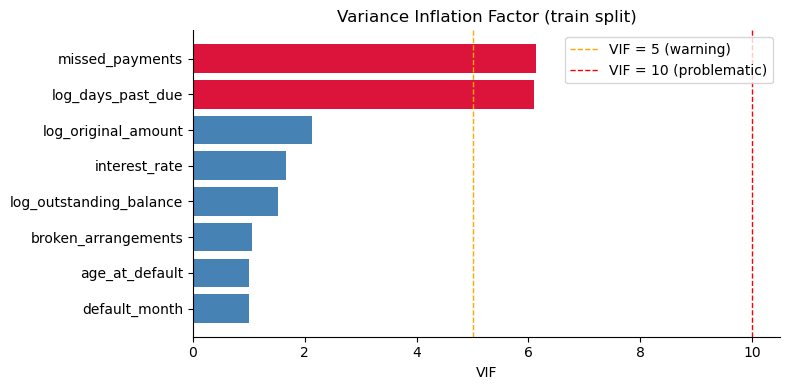

In [50]:
##########################################
## VIF computation on training data     ##
## training data                        ##
##########################################
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant  # adds an intercept column, required for correct VIF on older statsmodels versions

# VIF computation on train split
# Only keep features with at least 80% non-null coverage, since VIF requires
# dropping every row with any missing value across the feature set
vif_features = [c for c in cont_features if train_acc_clean[c].notna().mean() > 0.8]

# astype(float) avoids a dtype=object array if any boolean columns are
# ever added to cont_features (mixing float64 and bool breaks np.isfinite
# inside statsmodels' OLS call)
vif_data = train_acc_clean[vif_features].dropna().astype(float)

# Add a constant column: without it, some statsmodels versions compute VIF
# on uncentered data, which can wildly inflate values for features not
# centered near zero
vif_data_c = add_constant(vif_data)

# variance_inflation_factor regresses each feature on all the others in turn,
# so it is called once per feature, passing the feature's column position.
# Skip index 0, that's the constant column itself, not a real feature
vif_vals = [variance_inflation_factor(vif_data_c.values, i) for i in range(1, vif_data_c.shape[1])]
vif_df = pd.DataFrame({'feature': vif_features, 'VIF': vif_vals}).sort_values('VIF', ascending=False)
print(vif_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
# Colour bars red once VIF crosses the "warning" threshold of 5
colours = ['crimson' if v > 5 else 'steelblue' for v in vif_df['VIF']]
ax.barh(vif_df['feature'][::-1], vif_df['VIF'][::-1], color=colours[::-1])
ax.axvline(5,  color='orange', linestyle='--', linewidth=1, label='VIF = 5 (warning)')
ax.axvline(10, color='red',    linestyle='--', linewidth=1, label='VIF = 10 (problematic)')
ax.set_xlabel('VIF')
ax.set_title('Variance Inflation Factor (train split)')
ax.legend()
plt.tight_layout()
plt.show()

**QUESTION:** If two features have high VIF, what are your options? Consider:
removing one, combining them, or using a regularised model. What are the
trade-offs of each approach?

### 7.5 Imputation (fit on train, apply to all)

We use **group-wise mode imputation** for MNAR columns (impute within debt type group) and **median/mode imputation** for other columns.


<span style="color:red">**This is critical:**</span> 
- Imputation parameters are computed on the <span style="color:red">**training set only**</span>  and applied to val and test. 
- Using val/test statistics to impute would introduce information leakage from future data.

**Other imputation techniques worth exploring beyond this tutorial:**
- **KNN imputation**: fills a missing value using the average of the k most similar rows (by the other features), captures relationships between features that a simple group mode ignores
- **Multiple Imputation by Chained Equations (MICE)**: iteratively models each column with missing values as a function of the other columns, repeated across several imputed datasets to also capture imputation uncertainty
- **Regression imputation**: fits a model (e.g. linear/logistic regression) to predict the missing column from the other columns, more informed than a group mode, but can understate the imputed values' variance if used naively
- **Missingness indicator**: instead of (or alongside) filling the value, add a binary flag column marking which rows were originally missing, useful when the *fact* of being missing is itself informative, as we saw with the MNAR pattern in this dataset
- **Model-based imputers that handle missingness natively**: some algorithms (e.g. gradient-boosted trees like XGBoost/LightGBM) can split on missing values directly, removing the need to impute at all for those models

In [34]:
# Group-wise imputation for MNAR columns

# First, map the dominant (most frequent) debt type to each debtor, since a
# debtor can hold several accounts and we impute at the debtor level
acc_split_map = acc_clean.groupby('debtor_id')['debt_type'].agg(
    lambda x: x.dropna().mode()[0] if len(x.dropna()) > 0 else np.nan).to_dict()
debtor_clean['dominant_debt_type'] = debtor_clean['debtor_id'].map(acc_split_map)

# Fit the group modes on the train split only, so val/test never influence the imputed value
train_debtors = debtor_clean[debtor_clean['split'] == 'train']
mnar_cols = ['income_band', 'employment_status']
group_modes = {}
for col in mnar_cols:
    # For each debt-type group, take the most frequent non-null value
    group_modes[col] = (train_debtors.groupby('dominant_debt_type')[col]
                        .agg(lambda x: x.mode()[0] if x.notna().any() else np.nan))
    print(f'Group modes for {col}:')
    print(group_modes[col].to_string())
    print()

Group modes for income_band:
dominant_debt_type
Broadband / internet        20k-40k
Buy now pay later (BNPL)    20k-40k
Credit card                 20k-40k
Electricity arrears         20k-40k
Gas arrears                 20k-40k
Medical bill                20k-40k
Mobile phone contract       20k-40k
Personal loan               20k-40k
Water arrears               20k-40k

Group modes for employment_status:
dominant_debt_type
Broadband / internet        Employed full-time
Buy now pay later (BNPL)    Employed full-time
Credit card                 Employed full-time
Electricity arrears         Employed full-time
Gas arrears                 Employed full-time
Medical bill                Employed full-time
Mobile phone contract       Employed full-time
Personal loan               Employed full-time
Water arrears               Employed full-time



In [35]:
# Apply group-wise imputation to all splits
def impute_group_wise(df, col, group_col, group_modes):
    """Fills missing values in one column using a pre-fitted group mode lookup.

    Args:
        df (pd.DataFrame): The table to impute (any split; the imputation
            values themselves were already fitted on train only).
        col (str): Name of the column to impute.
        group_col (str): Name of the grouping column (e.g. dominant_debt_type)
            used to look up the correct mode for each row.
        group_modes (dict): Maps column name -> pd.Series of group -> mode,
            as produced by the group_modes fitting step above.

    Returns:
        pd.DataFrame: A copy of df with the missing values in col filled in
            wherever a matching group mode was found.
    """
    df = df.copy()
    # Only the rows that are actually missing need to be touched
    null_mask = df[col].isna()
    # Look up each missing row's group, then that group's fitted mode
    df.loc[null_mask, col] = df.loc[null_mask, group_col].map(group_modes[col])
    return df

# Apply the fitted group modes to every split (train, val, test alike)
for col in mnar_cols:
    debtor_clean = impute_group_wise(debtor_clean, col, 'dominant_debt_type', group_modes)

# education_level has no strong MNAR signal, so a single flat mode
# (fitted on train) is enough
edu_mode = train_debtors['education_level'].mode()[0]
debtor_clean['education_level'] = debtor_clean['education_level'].fillna(edu_mode)

# age_at_default: median imputation by debt type, fitted on train. 
# Falls back to the overall train median if a debt type has no train examples.
train_acc_clean2 = acc_clean[acc_clean['split'] == 'train']
age_median_by_type = train_acc_clean2.groupby('debt_type')['age_at_default'].median()
acc_clean['age_at_default'] = acc_clean.apply(
    lambda r: age_median_by_type.get(r['debt_type'], train_acc_clean2['age_at_default'].median())
    if pd.isna(r['age_at_default']) else r['age_at_default'], axis=1)

print('Imputation complete.')
null_check_cols = ['income_band','employment_status','education_level']
for col in null_check_cols:
    pct = debtor_clean[col].isna().mean() * 100
    print(f'  {col}: {pct:.1f}% null remaining')

Imputation complete.
  income_band: 0.1% null remaining
  employment_status: 0.1% null remaining
  education_level: 0.0% null remaining


#### 7.5b Do continuous features differ by repayment class? (Mann-Whitney U)

Now that the MNAR columns have been imputed, we check whether the continuous account-level features actually differ between the two preview repayment classes. We use the **Mann-Whitney U test** rather than a two-sample t-test because several of these features (amounts, days past due) are right-skewed even after a log transform, and Mann-Whitney does not assume normality.

$$H_0: \text{the two groups come from the same distribution}$$

Documentation: [scipy.stats.mannwhitneyu](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html)

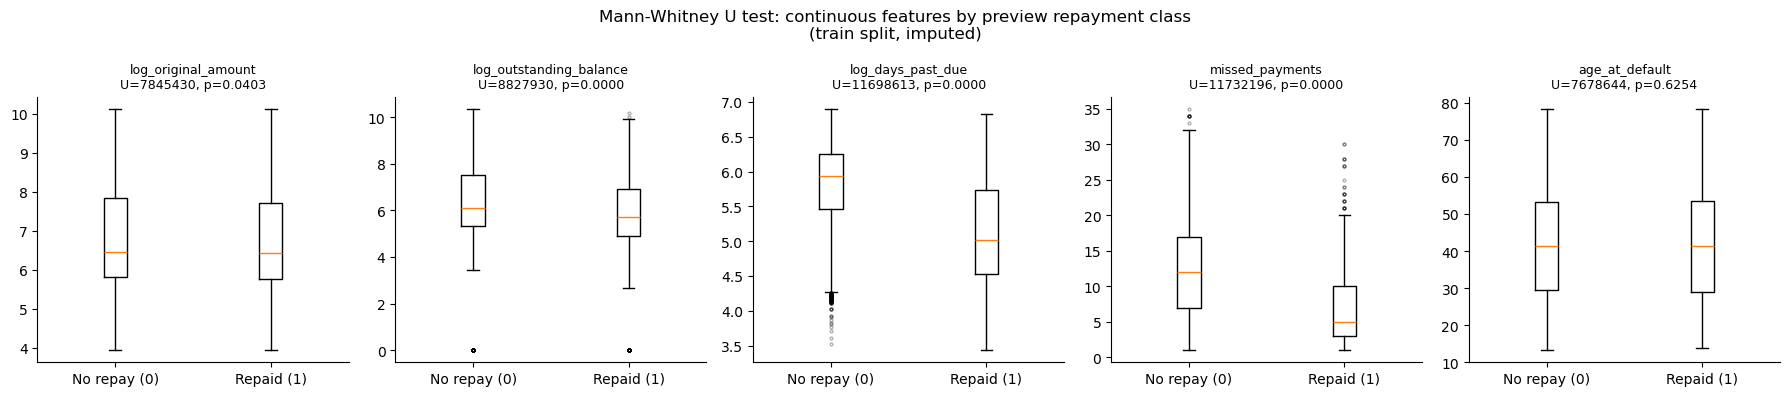

Mann-Whitney U test results (train split, imputed features):
  log_original_amount          U=     7845430  p=0.0403  -> significant difference
  log_outstanding_balance      U=     8827930  p=0.0000  -> significant difference
  log_days_past_due            U=    11698613  p=0.0000  -> significant difference
  missed_payments              U=    11732196  p=0.0000  -> significant difference
  age_at_default               U=     7678644  p=0.6254  -> no significant difference


In [36]:
# Refresh the accounts frame post-imputation and reattach the preview
# repayment flag computed in Section 7.3b
train_acc_imputed = acc_clean[acc_clean['split'] == 'train'].copy()
train_acc_imputed['repayment_preview'] = (
    train_acc_imputed['account_id'].map(repayment_preview_flag).fillna(0).astype(int))

mw_features = ['log_original_amount', 'log_outstanding_balance',
               'log_days_past_due', 'missed_payments', 'age_at_default']

fig, axes = plt.subplots(1, len(mw_features), figsize=(18, 4))

for i, col in enumerate(mw_features):
    # Split the feature's values by preview repayment class
    group0 = train_acc_imputed.loc[train_acc_imputed['repayment_preview'] == 0, col].dropna()
    group1 = train_acc_imputed.loc[train_acc_imputed['repayment_preview'] == 1, col].dropna()

    # Mann-Whitney U: non-parametric alternative to the two-sample t-test
    u_stat, p_val = stats.mannwhitneyu(group0, group1, alternative='two-sided')

    # Boxplot split by preview repayment class
    axes[i].boxplot([group0, group1], labels=['No repay (0)', 'Repaid (1)'],
                    flierprops={'marker': 'o', 'markersize': 2, 'alpha': 0.3})
    axes[i].set_title(f'{col}\nU={u_stat:.0f}, p={p_val:.4f}', fontsize=9)

plt.suptitle('Mann-Whitney U test: continuous features by preview repayment '
             'class\n(train split, imputed)', fontsize=12)
plt.tight_layout()
plt.show()

print('Mann-Whitney U test results (train split, imputed features):')
for col in mw_features:
    group0 = train_acc_imputed.loc[train_acc_imputed['repayment_preview'] == 0, col].dropna()
    group1 = train_acc_imputed.loc[train_acc_imputed['repayment_preview'] == 1, col].dropna()
    u_stat, p_val = stats.mannwhitneyu(group0, group1, alternative='two-sided')
    conclusion = 'significant difference' if p_val < 0.05 else 'no significant difference'
    print(f'  {col:<28} U={u_stat:>12.0f}  p={p_val:.4f}  -> {conclusion}')

**QUESTION:** A statistically significant Mann-Whitney result does not automatically mean a feature is useful for prediction. What else would you want to know about the size of the difference before relying on this feature?

### 7.6 Encoding (fit on train, apply to all)

- **Ordinal encoding** for ordered categories: `income_band`, `education_level`
- **One-hot encoding** for nominal categories: `debt_type`, `gender`, `employment_status`, etc.

Documentation: [sklearn OrdinalEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html)  
Documentation: [sklearn OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)

In [37]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

# Ordinal encoding: these two categories have a natural order, so encoding
# them 0, 1, 2, ... preserves information that one-hot encoding would throw away
ordinal_mappings = {
    'income_band': ['Under 10k', '10k-20k', '20k-40k', '40k-60k', 'Above 60k'],
    'education_level': ['Primary (basisschool)', 'Secondary (VMBO/MAVO)',
                        'Vocational (MBO)', 'Bachelor (HBO/WO)', 'Master and above'],
}

for col, order in ordinal_mappings.items():
    if col in debtor_clean.columns:
        # handle_unknown + unknown_value covers any category not seen at fit time
        enc = OrdinalEncoder(categories=[order], handle_unknown='use_encoded_value', unknown_value=-1)
        # Fit on train only; fillna('unknown') keeps missing rows from
        # crashing the encoder while still marking them clearly
        enc.fit(train_debtors[[col]].fillna('unknown'))
        debtor_clean[f'{col}_encoded'] = enc.transform(debtor_clean[[col]].fillna('unknown'))

# One-hot encoding for nominal (unordered) categorical columns
nominal_cols = ['debt_type', 'gender', 'employment_status', 'household_type',
                'urban_category', 'city', 'status']

encoded_dfs = []
for col in nominal_cols:
    # Each column lives in either the accounts table or the debtor table
    df_source = acc_clean if col in acc_clean.columns else debtor_clean
    if col not in df_source.columns:
        continue

    # Fit the encoder on the train rows of this column only
    train_vals = df_source[df_source['split'] == 'train'][[col]].fillna('unknown')
    # drop='first' avoids the dummy variable trap for linear models;
    # handle_unknown='ignore' means an unseen category at transform time
    # becomes all-zeros rather than raising an error
    enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first')
    enc.fit(train_vals)

    # Transform every split using the train-fitted encoder
    encoded = enc.transform(df_source[[col]].fillna('unknown'))
    col_names = [f'{col}_{c}' for c in enc.get_feature_names_out()]
    encoded_df = pd.DataFrame(encoded, columns=col_names, index=df_source.index)
    # Carry the relevant id column along so this can be merged back later
    encoded_df['account_id'] = df_source['account_id'] if 'account_id' in df_source.columns else df_source['debtor_id']
    encoded_dfs.append(encoded_df)
    print(f'  {col}: {encoded.shape[1]} dummy columns created')

print('\nEncoding complete.')

  debt_type: 9 dummy columns created
  gender: 4 dummy columns created
  employment_status: 8 dummy columns created
  household_type: 4 dummy columns created
  urban_category: 5 dummy columns created
  city: 5 dummy columns created
  status: 4 dummy columns created

Encoding complete.


**QUESTION:** We used drop='first' for one-hot encoding. Why is dropping one category necessary for linear and logistic regression, and would it still be necessary for a decision tree?

## Section 8: Target derivation

The five supervised learning targets do not exist as columns in the raw data.
We derive them from `payment_transactions` and `contact_history_enriched`.

| Target | Source | Window | Definition |
|---|---|---|---|
| `repayment_probability` | payment_transactions | 90 days | 1 if any payment within 90 days of account_default_date |
| `repayment_amount` | payment_transactions | 90 days | Sum of amount_paid within 90 days |
| `response_probability` | contact_history | 30 days | 1 if any response outcome within 30 days |
| `complaint_risk` | contact_history | No window | 1 if any dispute/complaint outcome ever |
| `time_to_repayment` | payment_transactions | no fixed window | Days from account_default_date to first payment |


> <span style="font-size:15px; color:green"> **Window choice:** 90 days for repayment targets aligns with the Dutch industry
> standard for unsecured consumer debt collection. 
> 30 days for response probability reflects the standard contact cycle under the Wet incassokosten (WIK).</span>

In [38]:
# Parse dates needed for target derivation
tx_clean['tx_date_parsed']      = pd.to_datetime(tx_clean['transaction_date'], errors='coerce')
ch_clean['contact_date_parsed'] = pd.to_datetime(ch_clean['contact_date'],     errors='coerce')
acc_clean['default_date_parsed']= pd.to_datetime(acc_clean['account_default_date'], errors='coerce')

# Outcomes that count as a "response" or a "complaint", straight from the
# Dataset Specification's list of possible contact outcomes
RESPONSE_OUTCOMES = {
    'Spoke to debtor', 'Promise to pay', 'Refused to pay', 'Disputed debt',
    'Arrangement agreed', 'Email replied', 'Complaint raised'
}
COMPLAINT_OUTCOMES = {'Disputed debt', 'Complaint raised'}

# repayment_probability and repayment_amount (90-day window) -----------------

# Attach each account's default date to every one of its transactions
tx_with_default = tx_clean.merge(
    acc_clean[['account_id','default_date_parsed']], on='account_id', how='left')
tx_with_default['days_since_default'] = (
    tx_with_default['tx_date_parsed'] - tx_with_default['default_date_parsed']).dt.days

# Keep only transactions inside the 90-day window, that occurred on or after
# the default date, and that are not flagged as cross-file inconsistent
tx_90 = tx_with_default[
    (tx_with_default['days_since_default'] >= 0) &
    (tx_with_default['days_since_default'] <= 90) &
    (~tx_with_default['date_inconsistency'])
]

# One row per account: whether they paid anything, how much in total, and
# how many days until their first payment
repayment_agg = tx_90.groupby('account_id').agg(
    repayment_probability = ('amount_paid', lambda x: 1 if (x > 0).any() else 0),
    repayment_amount      = ('amount_paid', 'sum'),
    time_to_repayment     = ('days_since_default', 'min')
).reset_index()

# Accounts with zero matching transactions never appear in repayment_agg, so
# left-join from the full account list and fill the resulting gaps
all_accounts = acc_clean[['account_id']].copy()
targets = all_accounts.merge(repayment_agg, on='account_id', how='left')
targets['repayment_probability'] = targets['repayment_probability'].fillna(0).astype(int)
targets['repayment_amount']      = targets['repayment_amount'].fillna(0)
# time_to_repayment stays NaN for non-payers; a fabricated 0 or -1 would
# quietly bias any model trained on it

# response_probability (30-day window) ----------------------------------------

# Attach each account's default date to every one of its contact attempts
ch_with_default = ch_clean.merge(
    acc_clean[['account_id','default_date_parsed']], on='account_id', how='left')
ch_with_default['days_since_default'] = (
    ch_with_default['contact_date_parsed'] - ch_with_default['default_date_parsed']).dt.days

# Keep only contacts inside the 30-day window
ch_30 = ch_with_default[
    (ch_with_default['days_since_default'] >= 0) &
    (ch_with_default['days_since_default'] <= 30)
]
ch_30['is_response'] = ch_30['outcome'].isin(RESPONSE_OUTCOMES)

# One row per account: whether any of their contacts got a response
response_agg = ch_30.groupby('account_id')['is_response'].any().astype(int).reset_index()
response_agg.columns = ['account_id', 'response_probability']
targets = targets.merge(response_agg, on='account_id', how='left')
targets['response_probability'] = targets['response_probability'].fillna(0).astype(int)

# complaint_risk (no window; a complaint ever counts) --------------------------
ch_clean['is_complaint'] = ch_clean['outcome'].isin(COMPLAINT_OUTCOMES)
complaint_agg = ch_clean.groupby('account_id')['is_complaint'].any().astype(int).reset_index()
complaint_agg.columns = ['account_id', 'complaint_risk']
targets = targets.merge(complaint_agg, on='account_id', how='left')
targets['complaint_risk'] = targets['complaint_risk'].fillna(0).astype(int)

# Carry the split label along so every downstream target analysis can be
# filtered to train only
targets = targets.merge(acc_clean[['account_id','split']], on='account_id', how='left')

print('Target derivation complete.')
targets[['repayment_probability','repayment_amount','response_probability',
               'complaint_risk','time_to_repayment']].describe().round(3)

Target derivation complete.


,repayment_probability,repayment_amount,response_probability,complaint_risk,time_to_repayment
count,13945.000,13945.000,13945.000,13945.000,4121.000
mean,0.296,32.356,0.078,0.168,34.233
std,0.456,90.101,0.269,0.374,25.327
min,0.000,0.000,0.000,0.000,0.000
25%,0.000,0.000,0.000,0.000,12.000
50%,0.000,0.000,0.000,0.000,29.000
75%,1.000,10.470,0.000,0.000,53.000
max,1.000,1227.570,1.000,1.000,90.000


**QUESTION:** repayment_probability and repayment_amount share the same 90-day window and the same underlying transactions. What could go wrong if you trained separate models for these two targets without ever checking how consistent their predictions are with each other?


### 8.1 Class imbalance

**Class imbalance and the accuracy paradox**

A dataset is **imbalanced** when one class is significantly more frequent than
another. In our case, most debtors do NOT repay within 90 days: the positive
class (repaid) is the minority.

This creates the **accuracy paradox**: a naive model that predicts *everyone* as
class 0 (no repayment) achieves high accuracy by doing nothing useful.

$$\text{Naive accuracy} = \frac{N_{\text{majority}}}{N_{\text{total}}}$$

For example, if 70% of debtors do not repay, the naive model achieves 70% accuracy
while identifying zero actual repayers, which is useless for the agency.

**Some methods to deal with class imbalance:**

| Method | How it works | When to use |
|---|---|---|
| **Class weights** | Assigns a higher penalty to misclassifying the minority class in the loss function, so the model is pushed to pay more attention to it without changing the data itself | Simple to apply (`class_weight='balanced'` in sklearn), no extra synthetic data, good default first attempt |
| **SMOTE** | Synthesises new minority-class examples by interpolating between existing minority points and their nearest minority neighbours | When the minority class has too few examples for class weights alone to help, and you want genuinely new (not duplicated) synthetic samples |
| **Threshold tuning** | Moves the classification cutoff away from the default 0.5, trading precision for recall (or vice versa) based on which error is more costly | After training, when you need to align the model's decisions with the actual cost of false positives vs false negatives for the business |
| **Precision-Recall AUC** | An evaluation metric, not a fix, that summarises the precision/recall trade-off across all thresholds, unlike ROC-AUC it isn't inflated by a large true-negative count | Whenever you're reporting performance on an imbalanced target, so you're not misled by a high but meaningless ROC-AUC |

We will use **class weights** as our running approach across these tutorials, since it requires no changes to the data itself. 
Other resampling techniques are still worth knowing about:

- **Random oversampling**: duplicates existing minority-class rows; simple, but can cause overfitting since no new information is added
- **Random undersampling**: drops majority-class rows; simple, but discards potentially useful data, risky on an already modest dataset
- **SMOTE**: see table above
- **ADASYN**: like SMOTE, but generates more synthetic samples near the decision boundary, where the classes are hardest to separate, rather than uniformly
- **Borderline-SMOTE**: only synthesises new samples from minority points near the boundary, ignoring "safe" minority points far from it
- **SMOTETomek / SMOTEENN**: combine SMOTE's oversampling with an undersampling cleanup step, removing ambiguous or noisy points after synthesising


Documentation: [sklearn class_weight](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html)  
Documentation: [imbalanced-learn SMOTE](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html)
```

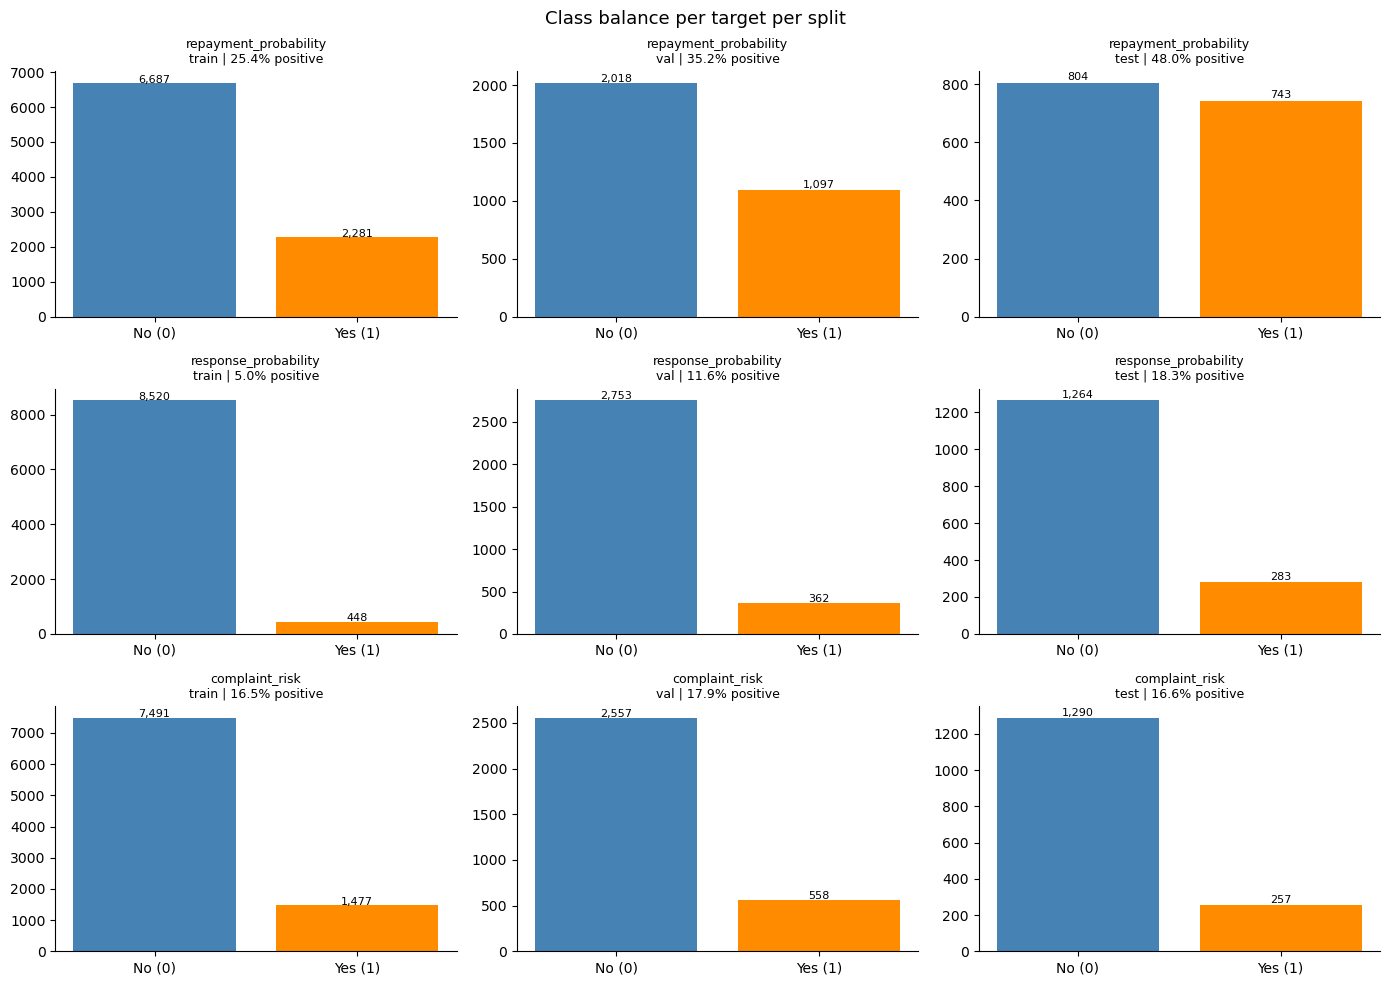

In [39]:
# Class balance analysis per split
binary_targets = ['repayment_probability', 'response_probability', 'complaint_risk']

fig, axes = plt.subplots(len(binary_targets), 3, figsize=(14, 10))

for i, target in enumerate(binary_targets):
    for j, split in enumerate(['train', 'val', 'test']):
        # Isolate this target's values for this split
        split_data = targets[targets['split'] == split][target].dropna()
        # Count how many 0s and 1s, keeping both categories even if one is empty
        counts = split_data.value_counts().reindex([0, 1], fill_value=0)
        pct_positive = counts[1] / counts.sum() * 100

        bars = axes[i, j].bar(['No (0)', 'Yes (1)'], counts.values,
                               color=['steelblue', 'darkorange'])
        axes[i, j].set_title(f'{target}\n{split} | {pct_positive:.1f}% positive', fontsize=9)
        # Label each bar with its raw count for readability
        for bar, val in zip(bars, counts.values):
            axes[i, j].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                            f'{val:,}', ha='center', fontsize=8)

plt.suptitle('Class balance per target per split', fontsize=13)
plt.tight_layout()
plt.show()

**QUESTION:** complaint_risk is the most imbalanced of the three binary targets. Before you even train a model, what does that imbalance tell you about how costly complaints are to the business relative to how often they occur?

In [40]:
# Accuracy paradox illustration
print('=== Accuracy Paradox ===')
print('If we predict class 0 for every account (naive classifier):\n')
train_targets = targets[targets['split'] == 'train']
for target in binary_targets:
    data = train_targets[target].dropna()
    # A naive "always predict 0" classifier's accuracy equals the majority
    # class share, since it is right exactly whenever the true label is 0
    majority_class_pct = (data == 0).mean() * 100
    print(f'{target}:')
    print(f'  Naive accuracy (predict all 0): {majority_class_pct:.1f}%')
    print(f'  Positive class rate:            {100-majority_class_pct:.1f}%')
    print(f'  Imbalance ratio:                {(data==0).sum()}/{(data==1).sum()} = {(data==0).sum()/(data==1).sum():.1f}:1')
    print()

=== Accuracy Paradox ===
If we predict class 0 for every account (naive classifier):

repayment_probability:
  Naive accuracy (predict all 0): 74.6%
  Positive class rate:            25.4%
  Imbalance ratio:                6687/2281 = 2.9:1

response_probability:
  Naive accuracy (predict all 0): 95.0%
  Positive class rate:            5.0%
  Imbalance ratio:                8520/448 = 19.0:1

complaint_risk:
  Naive accuracy (predict all 0): 83.5%
  Positive class rate:            16.5%
  Imbalance ratio:                7491/1477 = 5.1:1



In [41]:
# QUESTION illustration: precision-recall for imbalanced targets
from sklearn.metrics import f1_score, precision_score, recall_score

print('Naive classifier metrics (all zeros) on train split:')
print(f'{"Target":<30} {"Accuracy":>10} {"F1":>8} {"Precision":>12} {"Recall":>8}')
print('-' * 72)
for target in binary_targets:
    data = train_targets[target].dropna().astype(int)
    # The naive classifier predicts 0 for every single row
    y_pred_naive = np.zeros(len(data), dtype=int)
    acc = (data.values == y_pred_naive).mean()
    # zero_division=0 avoids a warning when there are no predicted positives
    f1  = f1_score(data.values, y_pred_naive, zero_division=0)
    pr  = precision_score(data.values, y_pred_naive, zero_division=0)
    rec = recall_score(data.values, y_pred_naive, zero_division=0)
    print(f'{target:<30} {acc:>10.3f} {f1:>8.3f} {pr:>12.3f} {rec:>8.3f}')

print('\n-> F1=0 and Recall=0 expose the naive classifier for what it is: useless.')
print('   We will use F1-score and Precision-Recall AUC as our primary metrics.')

Naive classifier metrics (all zeros) on train split:
Target                           Accuracy       F1    Precision   Recall
------------------------------------------------------------------------
repayment_probability               0.746    0.000        0.000    0.000
response_probability                0.950    0.000        0.000    0.000
complaint_risk                      0.835    0.000        0.000    0.000

-> F1=0 and Recall=0 expose the naive classifier for what it is: useless.
   We will use F1-score and Precision-Recall AUC as our primary metrics.


**QUESTION:** For the debt collection use case, which is more costly:
a **false negative** (predicting a debtor won't pay when they will) or a
**false positive** (predicting they will pay when they won't)? How does this
affect which metric you should optimise?

**QUESTION (follow-up):** If you had to justify a specific cost ratio between these two errors to the agency before choosing a metric, what would you ask them for, and how would a wrong assumption about that ratio change which threshold you'd pick?

### 8.2 Repayment amount distribution and log transform

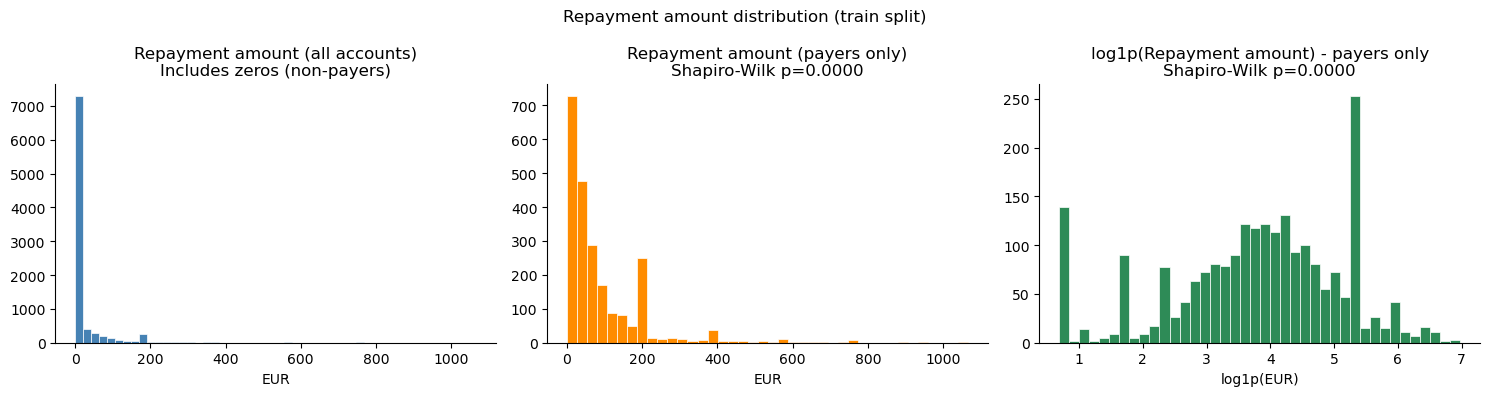

log_repayment_amount column created.
Accounts with zero repayment amount (non-payers): 9,824


In [42]:
# Repayment amount: distribution and log transform decision
train_amounts = targets[targets['split'] == 'train']['repayment_amount']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Left panel: raw distribution across ALL accounts, including the large
# spike of zeros from debtors who never paid
axes[0].hist(train_amounts, bins=50, color='steelblue', edgecolor='white', linewidth=0.5)
axes[0].set_title('Repayment amount (all accounts)\nIncludes zeros (non-payers)')
axes[0].set_xlabel('EUR')

# Middle panel: payers only, so the shape of the actually-interesting
# distribution isn't dominated by the zero spike
payers = train_amounts[train_amounts > 0]
stat, p = stats.shapiro(payers.sample(min(500, len(payers)), random_state=42))
axes[1].hist(payers, bins=40, color='darkorange', edgecolor='white', linewidth=0.5)
axes[1].set_title(f'Repayment amount (payers only)\nShapiro-Wilk p={p:.4f}')
axes[1].set_xlabel('EUR')

# Right panel: log1p transform of the payers-only distribution
log_amounts = np.log1p(payers)
stat_log, p_log = stats.shapiro(log_amounts.sample(min(500, len(log_amounts)), random_state=42))
axes[2].hist(log_amounts, bins=40, color='seagreen', edgecolor='white', linewidth=0.5)
axes[2].set_title(f'log1p(Repayment amount) - payers only\nShapiro-Wilk p={p_log:.4f}')
axes[2].set_xlabel('log1p(EUR)')

plt.suptitle('Repayment amount distribution (train split)', fontsize=12)
plt.tight_layout()
plt.show()

# log_repayment_amount is what all regression tutorials will actually train
# on; predictions get exponentiated back with expm1 for reporting
targets['log_repayment_amount'] = np.log1p(targets['repayment_amount'])
print('log_repayment_amount column created.')
print(f'Accounts with zero repayment amount (non-payers): {(targets["repayment_amount"]==0).sum():,}')

**QUESTION:** Why do we fit the log1p transform and check normality on payers only, rather than on all accounts including the zeros?

**A quick reminder before we compare them:** Section 8 derives five targets from the
raw transaction and contact data, each answering a different business question:

- `repayment_probability` — did the debtor pay anything within 90 days? (binary)
- `repayment_amount` — how much did they pay in that window? (continuous, EUR)
- `time_to_repayment` — how many days until their first payment? (continuous, NaN for non-payers)
- `response_probability` — did they respond to a contact attempt within 30 days? (binary)
- `complaint_risk` — did they raise a complaint or dispute, ever? (binary)

`repayment_probability` and `repayment_amount` share the same 90-day window and the
same underlying transactions, so we'd expect them to be closely related. The other
three come from a different table (contact history) on a different logic entirely,
so it's worth checking whether the correlations below match that intuition.

### 8.3 Target correlations

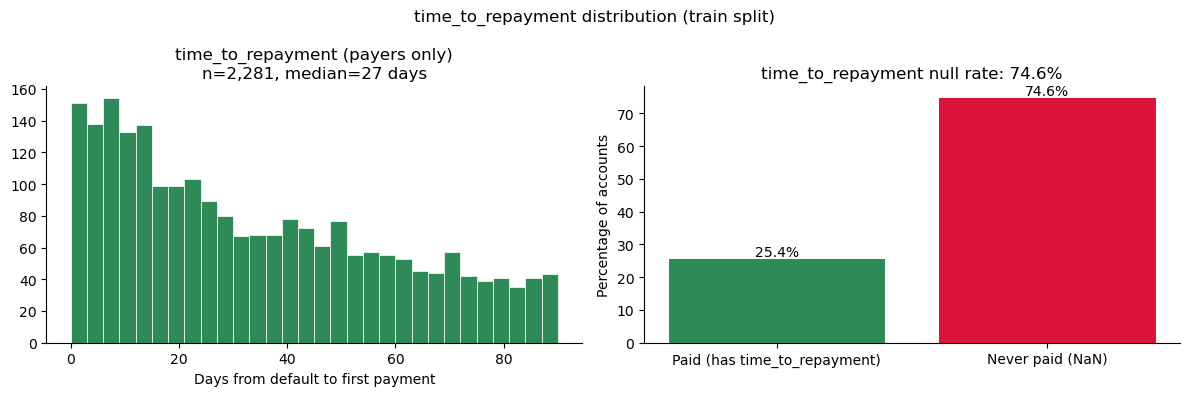

In [43]:
# time_to_repayment: distribution among payers only (NaN for accounts with no payment inside the 90-day window)
train_ttr = targets[targets['split'] == 'train']['time_to_repayment']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left panel: histogram of days to first payment, payers only
payers_ttr = train_ttr.dropna()
axes[0].hist(payers_ttr, bins=30, color='seagreen', edgecolor='white', linewidth=0.5)
axes[0].set_title(f'time_to_repayment (payers only)\n'
                  f'n={len(payers_ttr):,}, median={payers_ttr.median():.0f} days')
axes[0].set_xlabel('Days from default to first payment')

# Right panel: share of accounts that never paid inside the window,
# i.e. the share with a null time_to_repayment
null_pct = train_ttr.isna().mean()*100
axes[1].bar(['Paid (has time_to_repayment)', 'Never paid (NaN)'],
            [100 - null_pct, null_pct], color=['seagreen', 'crimson'])
axes[1].set_ylabel('Percentage of accounts')
axes[1].set_title(f'time_to_repayment null rate: {null_pct:.1f}%')
for i, val in enumerate([100 - null_pct, null_pct]):
    axes[1].text(i, val + 1, f'{val:.1f}%', ha='center', fontsize=10)

plt.suptitle('time_to_repayment distribution (train split)', fontsize=12)
plt.tight_layout()
plt.show()

**QUESTION:** time_to_repayment is missing for every debtor who never paid inside the window. If you dropped those rows before modelling this target, what kind of bias would you introduce?

**Correlation between the target variable**

*Pearson still works here, even though some targets are binary*

- Pearson correlation assumes both variables are continuous and linearly related. Naively, `repayment_probability`, `response_probability`, and `complaint_risk` (all binary 0/1) shouldn't qualify.
- But Pearson's formula doesn't actually require continuity, it only requires that arithmetic on the values (means, deviations, products) makes sense. For a 0/1-coded binary variable, arithmetic is well-defined, so the formula still computes cleanly, it just gets a different name depending on what it's applied to:

$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}$$

- **Point-biserial correlation** = Pearson's $r$ computed between one binary variable and one continuous variable (e.g. `repayment_probability` vs `repayment_amount`). It is not a different formula, it is literally the same Pearson formula, the "point-biserial" name is just what statisticians call this special case when one input happens to be binary.
- **Phi coefficient ($\phi$)** = Pearson's $r$ computed between two binary variables (e.g. `repayment_probability` vs `response_probability`). Again, the identical formula, just a different name for the 2x2 case. $\phi$ is also mathematically equivalent to Cramér's V restricted to a 2x2 table, so it connects directly back to the association measure used for categorical features in Section 7.3.
- **Why this only works because these targets are binary, not multi-category:** with exactly two categories, there's no ordering ambiguity, "0 vs 1" is unambiguous either way. With 3+ unordered categories (like `debt_type`), encoding them as 1, 2, 3, ... would impose a false numeric ordering that doesn't exist, which is exactly why Section 7.3 used Cramér's V and Kruskal-Wallis instead of Pearson for those.
- **One caveat**: the *sign* of a point-biserial or phi correlation only means something if the binary variable's 0/1 coding has a natural direction (e.g. `repayment_probability`: 1 = paid). For a binary variable with no inherent direction (e.g. `gender` coded arbitrarily as male=0/female=1), the magnitude `|r|` is still meaningful, but the sign flips depending on which category you happened to code as 1, so it needs to be reported alongside its coding to mean anything.

**Takeaway:** `train_tgt.corr(method='pearson')` on this target set is quietly computing three mathematically-equivalent things at once, point-biserial correlations, a phi coefficient, and ordinary Pearson $r$, depending on which pair of columns it's looking at. All three are valid because every categorical target here happens to be binary.

Documentation: [Point-biserial correlation](https://en.wikipedia.org/wiki/Point-biserial_correlation_coefficient)

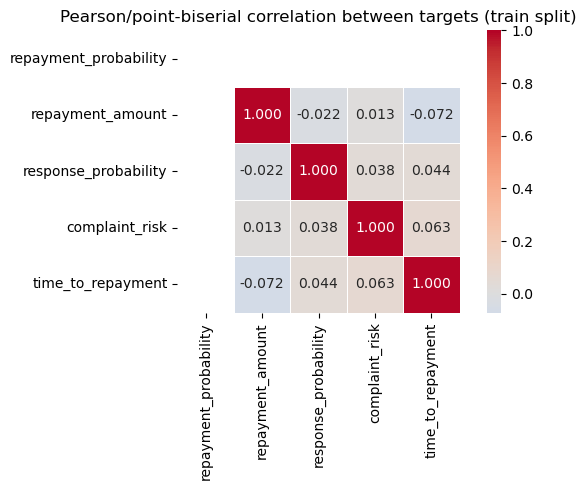


Note: repayment_probability and repayment_amount are correlated by construction
(debtors who pay have both a positive probability and a positive amount).
The multi-task ANN in Tutorial 3 exploits this shared structure.


In [44]:
# Pearson/point-biserial correlation between all five targets (train only)
target_cols = ['repayment_probability','repayment_amount','response_probability',
               'complaint_risk','time_to_repayment']

# dropna() here means only accounts with a non-null time_to_repayment (i.e. payers) contribute to this particular correlation matrix
train_tgt = targets[targets['split'] == 'train'][target_cols].dropna()

corr_tgt = train_tgt.corr(method='pearson')

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr_tgt, annot=True, fmt='.3f', cmap='coolwarm', center=0,
            ax=ax, square=True, linewidths=0.5)
ax.set_title('Pearson/point-biserial correlation between targets (train split)')
plt.tight_layout()
plt.show()

print('\nNote: repayment_probability and repayment_amount are correlated by construction')
print('(debtors who pay have both a positive probability and a positive amount).')
print('The multi-task ANN in Tutorial 3 exploits this shared structure.')

**QUESTION:** response_probability and complaint_risk both relate to contact outcomes, yet their correlation is much weaker than that between repayment_probability and repayment_amount. What does that suggest about whether these targets can share a representation in Tutorial 3's multi-task ANN model?

## Section 9: Split validation

Before saving, we validate that the three splits have compatible feature distributions.
Significant distribution shift between train and test is a warning sign that the model
may not generalise. This is known as **covariate shift**. This covariate shift can be tested using different tests depending on the nature of the feature variable, i.e., if they are continuous, binary, nominal or purely categorical data.

### 9.1 Checking drift in continuous features

**Kolmogorov-Smirnov (KS) test:** Used to test distributional different between two continuous data distributions. 

$$D = \sup_x |F_1(x) - F_2(x)|$$

where $F_1$ and $F_2$ are the empirical CDFs of the two samples.
A significant KS statistic ($p < 0.05$) indicates the distributions differ.

Documentation: [scipy.stats.ks_2samp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ks_2samp.html)

**Reading the $D_{critical}$ line in figure below**

- **$D$** is the KS test statistic: the largest vertical gap between the two samples' cumulative distributions, a number between 0 (identical) and 1 (no overlap).
- **$D_{critical}$** is the value D must exceed for the result to count as p < 0.05, computed from the two sample sizes being compared:
$$D_{critical} \approx 1.36\sqrt{\frac{n+m}{nm}}$$
- Larger samples give a **smaller** $D_{critical}$, so the same size of gap between distributions is easier to detect as "significant" the more data you have.
- The orange line on each chart is this critical value for that specific comparison's sample sizes, not a fixed rule of thumb. A bar crossing the line means p < 0.05, exactly, with nothing hidden or approximated.

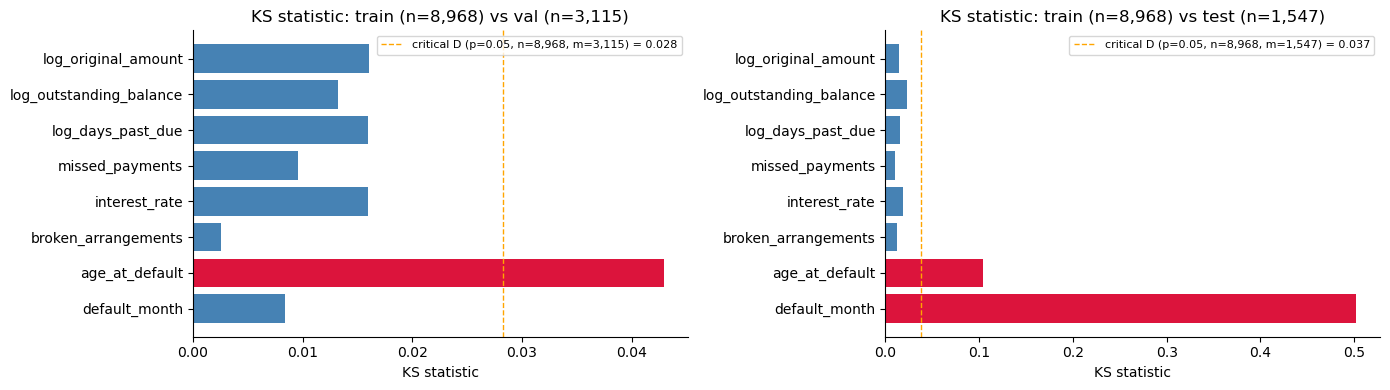

                feature  KS_train_val  p_train_val  KS_train_test  p_train_test
    log_original_amount        0.0160       0.5870         0.0149        0.9274
log_outstanding_balance        0.0132       0.8076         0.0229        0.4840
      log_days_past_due        0.0160       0.5940         0.0156        0.8991
        missed_payments        0.0095       0.9830         0.0099        0.9993
          interest_rate        0.0160       0.5893         0.0190        0.7203
    broken_arrangements        0.0025       1.0000         0.0122        0.9878
         age_at_default        0.0429       0.0004         0.1039        0.0000
          default_month        0.0084       0.9961         0.5023        0.0000


In [45]:
# KS test: train vs val, train vs test
from scipy.stats import ks_2samp

def ks_critical_value(n, m, alpha=0.05):
    """Computes the critical KS D-statistic for a given pair of sample sizes.

    Args:
        n (int): Size of the first sample.
        m (int): Size of the second sample.
        alpha (float): Significance level (default 0.05).

    Returns:
        float: The KS statistic value above which p < alpha, for these
            specific sample sizes. Unlike a fixed threshold, this changes
            with n and m, larger samples need a smaller D to be significant.
    """
    c_alpha = 1.36 if alpha == 0.05 else 1.63  # 1.63 corresponds to alpha=0.01
    return c_alpha * np.sqrt((n + m) / (n * m))

ks_results = []
cont_check_cols = ['log_original_amount', 'log_outstanding_balance',
                   'log_days_past_due', 'missed_payments', 'interest_rate',
                   'broken_arrangements', 'age_at_default', 'default_month']

train_acc_ks = acc_clean[acc_clean['split'] == 'train']
val_acc_ks   = acc_clean[acc_clean['split'] == 'val']
test_acc_ks  = acc_clean[acc_clean['split'] == 'test']

# Critical D depends only on the two sample sizes being compared, not on the
# feature, so it is the same for every row within each comparison
n_train, n_val, n_test = len(train_acc_ks), len(val_acc_ks), len(test_acc_ks)
crit_train_val  = ks_critical_value(n_train, n_val)
crit_train_test = ks_critical_value(n_train, n_test)

for col in cont_check_cols:
    if col not in acc_clean.columns:
        continue
    tr = train_acc_ks[col].dropna()
    va = val_acc_ks[col].dropna()
    te = test_acc_ks[col].dropna()
    if len(va) > 0 and len(te) > 0:
        ks_tv, p_tv = ks_2samp(tr, va)
        ks_tt, p_tt = ks_2samp(tr, te)
        ks_results.append({'feature': col,
                           'KS_train_val': ks_tv, 'p_train_val': p_tv,
                           'KS_train_test': ks_tt, 'p_train_test': p_tt})

ks_df = pd.DataFrame(ks_results)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, ks_col, p_col, crit, n1, n2, title in [
    (axes[0], 'KS_train_val',  'p_train_val',  crit_train_val,  n_train, n_val,
     f'KS statistic: train (n={n_train:,}) vs val (n={n_val:,})'),
    (axes[1], 'KS_train_test', 'p_train_test', crit_train_test, n_train, n_test,
     f'KS statistic: train (n={n_train:,}) vs test (n={n_test:,})')]:
    # Color directly from whether KS exceeds the critical value for THIS
    # comparison's sample sizes, so the color and the line always agree
    colours = ['crimson' if ks > crit else 'steelblue' for ks in ks_df[ks_col]]
    ax.barh(ks_df['feature'][::-1], ks_df[ks_col][::-1], color=colours[::-1])
    ax.axvline(crit, color='orange', linestyle='--', linewidth=1,
               label=f'critical D (p=0.05, n={n1:,}, m={n2:,}) = {crit:.3f}')
    ax.set_title(title)
    ax.set_xlabel('KS statistic')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()
print(ks_df[['feature','KS_train_val','p_train_val','KS_train_test','p_train_test']].round(4).to_string(index=False))

**QUESTION:**
What can we conclude from the result above?
A KS statistic can be small even when the two samples being compared are very different sizes, as train and test are here. Is a small KS statistic on its own enough to conclude the distributions truly match?

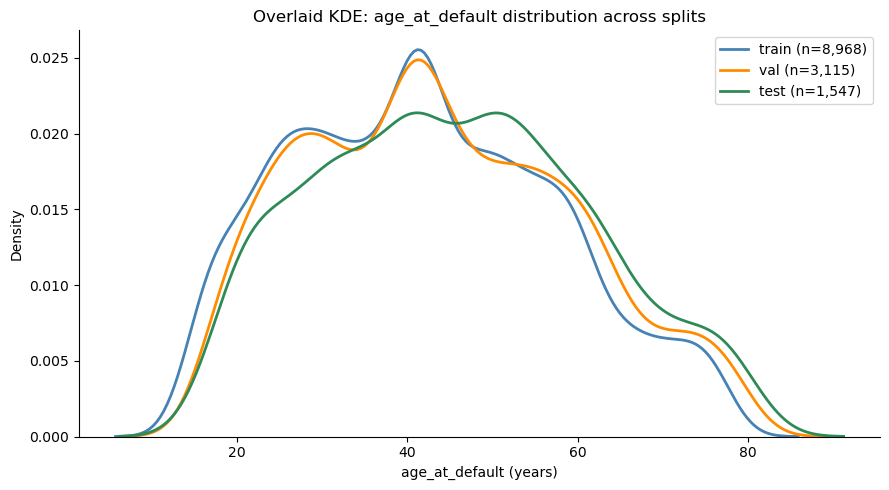

KS test train vs val: statistic=0.0429, p=0.0004
KS test train vs test: statistic=0.1039, p=0.0000


In [46]:
## Age at default distribution across splits (KDE), backed by the KS test
fig, ax = plt.subplots(figsize=(9, 5))

for split, colour in [('train', 'steelblue'), ('val', 'darkorange'), ('test', 'seagreen')]:
    split_ages = acc_clean[acc_clean['split'] == split]['age_at_default'].dropna()
    sns.kdeplot(split_ages, ax=ax, label=f'{split} (n={len(split_ages):,})',
                color=colour, linewidth=2)

ax.set_xlabel('age_at_default (years)')
ax.set_ylabel('Density')
ax.set_title('Overlaid KDE: age_at_default distribution across splits')
ax.legend()
plt.tight_layout()
plt.show()

# KS test to confirm numerically what the KDE overlay suggests visually
train_age = acc_clean[acc_clean['split'] == 'train']['age_at_default'].dropna()
for split in ['val', 'test']:
    split_age = acc_clean[acc_clean['split'] == split]['age_at_default'].dropna()
    ks_stat, ks_p = ks_2samp(train_age, split_age)
    print(f'KS test train vs {split}: statistic={ks_stat:.4f}, p={ks_p:.4f}')

### 9.2 Checking drift in categorical variables

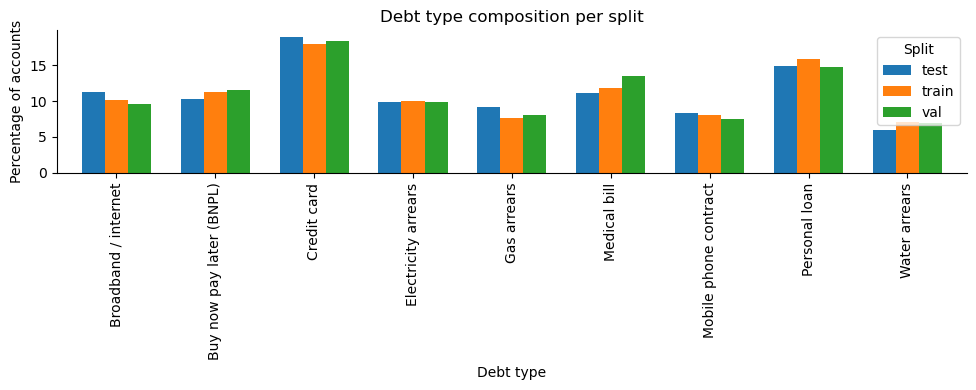

Debt type share vs train, sorted by largest deviation from train:
                          train    val   test dev_train_val dev_train_test max_dev_from_train
debt_type                                                                                    
Medical bill              11.9%  13.5%  11.2%          1.6%           0.7%               1.6%
Gas arrears                7.6%   8.1%   9.2%          0.5%           1.6%               1.6%
Broadband / internet      10.1%   9.6%  11.3%          0.6%           1.2%               1.2%
Water arrears              7.1%   6.9%   6.0%          0.2%           1.2%               1.2%
Personal loan             15.9%  14.7%  14.9%          1.1%           1.0%               1.1%
Buy now pay later (BNPL)  11.3%  11.6%  10.3%          0.3%           1.0%               1.0%
Credit card               17.9%  18.4%  18.9%          0.4%           1.0%               1.0%
Mobile phone contract      8.1%   7.5%   8.4%          0.7%           0.3%              

In [47]:
## Debt type composition across splits (concept drift check)

# Count accounts by debt_type within each split, then convert to a
# percentage of that split so splits of different sizes are comparable
debt_composition = (acc_clean[acc_clean['split'].isin(['train','val','test'])]
                    .groupby(['split','debt_type']).size()
                    .unstack(fill_value=0))
debt_pct = debt_composition.div(debt_composition.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 4))
debt_pct.T.plot(kind='bar', ax=ax, width=0.7)
ax.set_title('Debt type composition per split')
ax.set_xlabel('Debt type')
ax.set_ylabel('Percentage of accounts')
ax.tick_params(axis='x', rotation=90)
ax.legend(title='Split')
plt.tight_layout()
plt.show()

# Deviation from train's share, per debt type, matches how the KS test above
# is framed (train vs val, train vs test), rather than spread across all three
train_share = debt_pct.loc['train']
dev_val  = (debt_pct.loc['val']  - train_share).abs()
dev_test = (debt_pct.loc['test'] - train_share).abs()

comparison = pd.DataFrame({
    'train': train_share,
    'val': debt_pct.loc['val'],
    'test': debt_pct.loc['test'],
    'dev_train_val': dev_val,
    'dev_train_test': dev_test,
    'max_dev_from_train': pd.concat([dev_val, dev_test], axis=1).max(axis=1)
}).sort_values('max_dev_from_train', ascending=False)

# Format every numeric column with a % symbol for the printed table
comparison_display = comparison.round(1).applymap(lambda x: f'{x:.1f}%')

print('Debt type share vs train, sorted by largest deviation from train:')
print(comparison_display.to_string())

**QUESTION:** None of the debt types showed a meaningful deviation from train (all under 2 percentage points). Does this mean you can be confident the model will perform equally well on all debt types once deployed? What would this composition check miss even if every debt type were perfectly balanced across splits?


*Hint*: this analysis was scoped to `debt_type` alone. It says nothing about whether other categorical features (`urban_category`, `employment_status`, `city`) are
equally stable, and the KS test just before this section already found `age_at_default` genuinely drifting. A single feature's composition being fine doesn't generalise to "the whole dataset is fine."

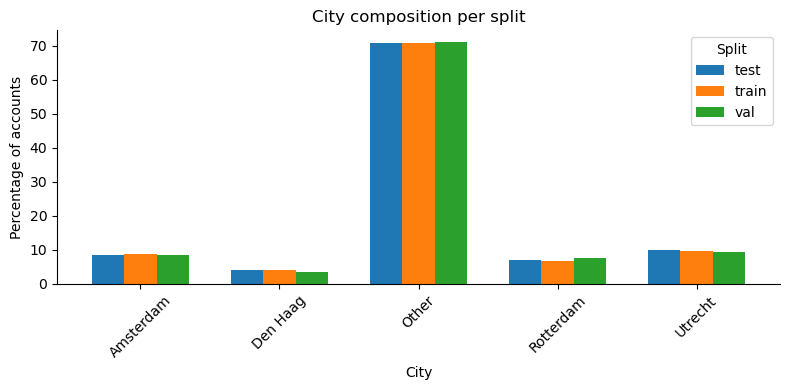

NameError: name 'train_share_city' is not defined

In [48]:
## City composition across splits (same check as debt_type, for a second feature)

city_composition = (acc_clean[acc_clean['split'].isin(['train','val','test'])]
                    .groupby(['split','city']).size()
                    .unstack(fill_value=0))
city_pct = city_composition.div(city_composition.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 4))
city_pct.T.plot(kind='bar', ax=ax, width=0.7)
ax.set_title('City composition per split')
ax.set_xlabel('City')
ax.set_ylabel('Percentage of accounts')
ax.tick_params(axis='x', rotation=45)
ax.legend(title='Split')
plt.tight_layout()
plt.show()

city_comparison = pd.DataFrame({
    'train': train_share_city,
    'val': city_pct.loc['val'],
    'test': city_pct.loc['test'],
    'dev_train_val': dev_val_city,
    'dev_train_test': dev_test_city,
    'max_dev_from_train': pd.concat([dev_val_city, dev_test_city], axis=1).max(axis=1)
}).sort_values('max_dev_from_train', ascending=False)

# Format every numeric column with a % symbol before printing
city_comparison = city_comparison.round(1).applymap(lambda x: f'{x:.1f}%')

print('City share vs train, sorted by largest deviation from train:')
print(city_comparison.to_string())

*Result*: 
- `city` composition is stable too, the largest deviation from train is
`Rotterdam` at 0.9 percentage points, even smaller than any debt type. 
- Two clean composition checks in a row is worth pausing on: it does not mean the dataset is
free of generalisation risk, only that these two specific features' marginal
distributions haven't shifted. The failure modes from the hint above (within-category
drift, small subgroup sample sizes, target-distribution shift) are still unverified
either way. 
- Note `Other` covers ~70% of every split, worth confirming that's
expected given the `postcode_to_city` ranges in Section 7.1, rather than those
ranges being too narrow for where most debtors actually live.

### 9.3 Checking drift in the target: Repayment amount distribution across splits (KDE)

The KS test above checks account-level features. Here we check the continuous target itself: does `repayment_amount` look the same across train, val, and test, or has its distribution shifted over time along with the debt-type composition seen above?

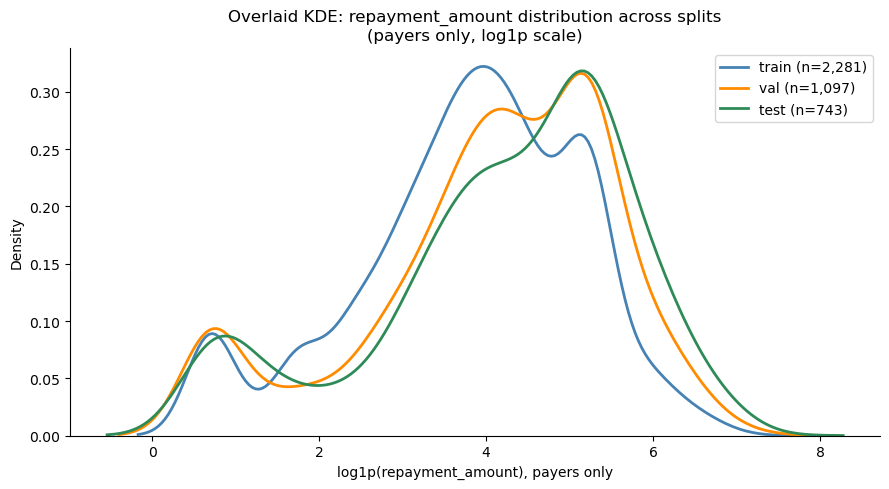

KS test: train vs val: statistic=0.1247, p=0.0000
KS test: train vs test: statistic=0.2009, p=0.0000


In [ ]:
# Overlaid KDE: does the repayment_amount distribution shift across splits?
fig, ax = plt.subplots(figsize=(9, 5))

for split, colour in [('train', 'steelblue'), ('val', 'darkorange'), ('test', 'seagreen')]:
    split_amounts = targets[targets['split'] == split]['repayment_amount']
    # Payers only: the large zero spike would dominate the density and
    # hide the shape differences that actually matter here
    split_amounts = split_amounts[split_amounts > 0]
    sns.kdeplot(np.log1p(split_amounts), ax=ax,
                label=f'{split} (n={len(split_amounts):,})', color=colour, linewidth=2)

ax.set_xlabel('log1p(repayment_amount), payers only')
ax.set_ylabel('Density')
ax.set_title('Overlaid KDE: repayment_amount distribution across splits\n'
             '(payers only, log1p scale)')
ax.legend()
plt.tight_layout()
plt.show()

# KS test to confirm numerically what the KDE overlay suggests visually
train_log_amt = np.log1p(
    targets[(targets['split']=='train') & (targets['repayment_amount']>0)]['repayment_amount'])
for split in ['val', 'test']:
    split_log_amt = np.log1p(
        targets[(targets['split']==split) & (targets['repayment_amount']>0)]['repayment_amount'])
    ks_stat, ks_p = ks_2samp(train_log_amt, split_log_amt)
    print(f'KS test: train vs {split}: statistic={ks_stat:.4f}, p={ks_p:.4f}')

**QUESTION:** The KS test confirms a real, substantial shift in `repayment_amount`, not just a large-sample artifact: statistic=0.125 (train vs val) and statistic=0.201 (train vs test), both clearing their respective critical D thresholds (~0.05) by 2-3x, and the drift gets worse the further out you look. Given that this is the target itself shifting, not just a feature, what would this imply about a regression model trained only on train's typical repayment amounts? What would you want to check next to understand *why* this drift is happening before deciding how to handle it?
</br>

**Checking the time splits:** the KS test found `repayment_amount` shifting significantly
across train/val/test (KS=0.125 val, KS=0.201 test), and none of the composition checks
(`debt_type`, `city`) or other continuous features explained it. Since the splits are
date-based, the natural next step is to look at `repayment_amount` against calendar time
directly, ignoring the split labels entirely, to see whether a time trend is the actual
driver.

In [ ]:
# Merge repayment_amount onto accounts so each row has both its default_year
# and how much that account actually repaid
yearly_trend = acc_clean.merge(
    targets[['account_id', 'repayment_amount']], on='account_id')

# Group by default_year and summarise repayment_amount three ways: mean
# (sensitive to the trend, but pulled by outliers), median (robust, but
# stuck at 0 here since most debtors don't pay), and count (sample size
# per year, worth checking before trusting the mean/median)
yearly_trend.groupby(acc_clean['default_year'])['repayment_amount'].agg(['mean', 'median', 'count'])

,mean,median,count
default_year,,,
2020.0,15.842057,0.0,2995
2021.0,20.496500,0.0,2997
2022.0,31.497473,0.0,3039
2023.0,43.334761,0.0,3132
2024.0,70.718648,0.0,1568


**What the results tell us:**

- Mean repayment amount roughly **quadruples** from 2020 (€15.84) to 2024 (€70.72), and
  the increase is accelerating: the 2023→2024 jump alone (+€27.38) is larger than the
  entire 2020→2022 increase
- Since train covers the earlier years and test skews toward the later ones, this trend
  alone plausibly explains most of the KS result, test simply contains more of the years
  where amounts are highest
- The median stays at €0.0 in every year, expected given the zero-spike structure from
  Section 8.2, most debtors don't pay at all, so it can't distinguish two different
  explanations for the rising mean: are payers paying more each year, or is a shrinking,
  higher-value subset of debtors driving the average up? 

**What this means for modelling (carried forward to modelling notebooks):**

- A train-vs-test performance gap on `repayment_amount` won't be purely about overfitting, part of it is genuine target drift, not something more regularisation can fix
- `default_year` and `default_month` are already in `cleaned_dataset.pkl`; including them as features would let a model learn this trend explicitly rather than being blindsided by it
- This is the date-based split correctly doing its job, exposing a realistic deployment challenge, not a flaw in how the split was constructed
- In a live system, a trend this strong (amounts roughly quadrupling 2020→2024) would be a direct argument for periodic retraining, a model frozen at deployment time only degrades further as the trend continues

## Section 10: Assemble feature matrix and save

**What `master` actually contains (saved later as `cleaned_dataset.pkl`):**

`master` is an **account-level** table, one row per account in `accounts.csv`, built by joining three things:

- **Engineered account features** from `acc_clean`: `log-transformed amounts`, `age_at_default`, `debt_type`, `city`, date-derived features, and data-quality flags (`balance_capped`, `default_date_imputed`)
- **Debtor demographics** from `debtor_clean`, joined via `debtor_id`: encoded income/education, employment status, household type, and the imputed MNAR columns from Section 7.5
- **The five derived targets** from `targets`, joined via `account_id`: `repayment_probability`, `repayment_amount`, `time_to_repayment`, `response_probability`, `complaint_risk`

**What it deliberately does *not* contain:** any raw columns from `contact_history_enriched.csv` (channel, agent_id, outcome, contact timing, email/call text, cost, etc.). Only the two *outcomes* derived from that table, `response_probability` and `complaint_risk`, make it into `master`, none of the contact-level features that could explain *why* a debtor responded or complained. That's by design: this table is scoped to account-level modelling, contact-level feature engineering belongs to whichever tutorial actually 
needs it. 

`contact_history_enriched.csv` stays on disk as its own file, and later Tutorials (starting from 4) load it directly rather than through this pickle.

In [ ]:
# Assemble the feature matrix
# Join all engineered features and targets onto accounts as the master table

# Columns coming from the accounts table (IDs, split label, engineered
# numeric features, and quality flags)
feature_cols_acc = ['account_id', 'debtor_id', 'split',
                    'log_original_amount', 'log_outstanding_balance', 'log_days_past_due',
                    'missed_payments', 'interest_rate', 'broken_arrangements',
                    'age_at_default', 'default_month', 'default_year',
                    'balance_capped', 'default_date_imputed',
                    'debt_type', 'status', 'city']

# Columns coming from the debtor table (demographics, already encoded
# where an ordinal encoding was applied)
feature_cols_debtor = ['debtor_id', 'gender', 'household_type',
                       'income_band_encoded', 'education_level_encoded',
                       'employment_status', 'urban_category',
                       'country_of_origin', 'born_in_netherlands']

# Defensive filter in case any expected column is missing upstream
feature_cols_debtor = [c for c in feature_cols_debtor if c in debtor_clean.columns]

# Start from accounts, left-join debtor features by debtor_id, then
# left-join the five derived targets by account_id
master = acc_clean[[c for c in feature_cols_acc if c in acc_clean.columns]].copy()

# feature_cols_debtor already starts with 'debtor_id' (the merge key), so it is used directly here rather than prefixing it again
master = master.merge(
    debtor_clean[[c for c in feature_cols_debtor if c in debtor_clean.columns]],
    on='debtor_id', how='left')
master = master.merge(targets.drop(columns=['split'], errors='ignore'),
                      on='account_id', how='left')

print(f'Feature matrix shape: {master.shape}')
print(f'Columns: {list(master.columns)}')
print()
print('Split sizes:')
print(master['split'].value_counts())
print()
print('Null rates in final feature matrix (top 10):')
null_final = master.isnull().mean().sort_values(ascending=False).head(10) * 100
print(null_final.round(2).to_string())

Feature matrix shape: (13945, 31)
Columns: ['account_id', 'debtor_id', 'split', 'log_original_amount', 'log_outstanding_balance', 'log_days_past_due', 'missed_payments', 'interest_rate', 'broken_arrangements', 'age_at_default', 'default_month', 'default_year', 'balance_capped', 'default_date_imputed', 'debt_type', 'status', 'city', 'gender', 'household_type', 'income_band_encoded', 'education_level_encoded', 'employment_status', 'urban_category', 'country_of_origin', 'born_in_netherlands', 'repayment_probability', 'repayment_amount', 'time_to_repayment', 'response_probability', 'complaint_risk', 'log_repayment_amount']

Split sizes:
split
train      8968
val        3115
test       1547
unknown     315
Name: count, dtype: int64

Null rates in final feature matrix (top 10):
time_to_repayment      70.45
born_in_netherlands     5.84
country_of_origin       5.84
household_type          4.85
gender                  2.56
urban_category          2.30
city                    2.30
default_month 

In [ ]:
import pickle, os

# Reuse DATA_DIR from the load cell so save and load can never drift apart
save_path = os.path.join(DATA_DIR, 'cleaned_dataset.pkl')

os.makedirs(DATA_DIR, exist_ok=True)
with open(save_path, 'wb') as f:
    pickle.dump(master, f)

assert os.path.exists(save_path), f'Save failed: {save_path} does not exist'

print(f'Saved: {save_path}')
print(f'  File size: {os.path.getsize(save_path) / 1024:.1f} KB')
print(f'  Total rows: {len(master):,}')
print(f'  Train rows: {(master.split=="train").sum():,}')
print(f'  Val rows:   {(master.split=="val").sum():,}')
print(f'  Test rows:  {(master.split=="test").sum():,}')
print(f'  Features:   {master.shape[1]} columns')

Saved: data/cleaned_dataset.pkl
  File size: 3293.2 KB
  Total rows: 13,945
  Train rows: 8,968
  Val rows:   3,115
  Test rows:  1,547
  Features:   31 columns


## Key takeaways

- **MNAR nulls** in `income_band`, `employment_status`, and `date_of_birth` are
  correlated with debt type. Standard mean imputation would introduce bias:
  we used group-wise imputation instead.

- **Structural cascades** mean `urban_category` and `born_in_netherlands` cannot
  be imputed independently from `postcode` and `country_of_origin`.

- **ANOVA** confirmed that `outstanding_balance` differs significantly across debt_type groups, and came out borderline (p ≈ 0.064) for `urban_category`, worth a closer look before concluding whether geography plays a role.

- **Class imbalance** is substantial. The naive classifier achieves high accuracy
  with zero recall. We will use F1-score and Precision-Recall AUC from Tutorial 1
  onward, and apply class weights to penalise misclassification of payers.

- **Temporal distribution shift**: BNPL and mobile phone accounts are
  underrepresented in train relative to test. Models may perform differently
  on these debt types in practice.

- **Test set is sacred:** all imputation, encoding, and scaling parameters
  were fitted on the training set only.

**Next:** Linear and logistic regression baseline models on `cleaned_dataset.pkl`.